> **Etapa actual: tendencias ambientales (secciones 26–31).** Se estudian los 120 meses de 2014–2023. La predicción queda pospuesta; los análisis anteriores de CONAF son asociativos.

# Validación, limpieza y exploración ambiental
**La Araucanía · enero de 2014–diciembre de 2023 · frecuencia mensual**

Usamos exclusivamente las tablas de `datos_mensuales_2014_2023`. La referencia vial de 2019 se revisa por separado. Los archivos originales se conservan; las copias limpias y el informe se escriben en `limpios/`.

**Objetivo:** comprobar la calidad, describir el ciclo anual, identificar anomalías y comparar comunas. Esta exploración no es un modelo de riesgo ni establece causalidad.

Ejecutar con el intérprete `.venv` del proyecto. Dependencias en `requirements-analisis.txt`.

In [1]:
%matplotlib inline
from pathlib import Path
import json, hashlib, unicodedata, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'datos_mensuales_2014_2023').is_dir())
DATA = ROOT / 'datos_mensuales_2014_2023'
OUTPUT = DATA / 'limpios'
EXPECTED_MONTHS = pd.date_range('2014-01-01', '2023-12-01', freq='MS')
MIN_COVERAGE = 80.0  # Criterio exploratorio configurable, no un estándar universal.
MONTH_LABELS = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
CORE = {
    'temperature_2m_c': ('Temperatura media', '°C', '#C74A3A'),
    'precipitation_mm': ('Precipitación mensual', 'mm/mes', '#277DA8'),
    'relative_humidity_2m_pct': ('Humedad relativa', '%', '#39836B'),
    'soil_moisture_0_10cm_kgm2': ('Humedad del suelo 0–10 cm', 'kg/m²', '#94713F'),
    'wind_speed_10m_ms': ('Viento a 10 m', 'm/s', '#7B60A8'),
    'aod_550': ('Aerosoles AOD 550 nm', 'adimensional', '#555F69'),
}
UNITS = {
    'temperature_2m_c': '°C', 'dewpoint_2m_c': '°C',
    'specific_humidity_2m_kgkg': 'kg/kg', 'wind_u_10m_ms': 'm/s',
    'wind_v_10m_ms': 'm/s', 'wind_speed_lowest_model_ms': 'm/s',
    'soil_moisture_0_10cm_kgm2': 'kg/m²', 'soil_temperature_0_10cm_c': '°C',
    'aod_550': 'adimensional', 'precipitation_mm': 'mm/mes',
    'temperature_monthly_max_c': '°C', 'relative_humidity_2m_pct': '%',
    'wind_speed_10m_ms': 'm/s', 'temperature_monthly_peak_area_mean_c': '°C',
}
SOIL = ['soil_moisture_0_10cm_kgm2', 'soil_temperature_0_10cm_c']
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 26)
print(f'Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}')

Python 3.13.18 · pandas 3.1.1 · numpy 2.5.4


## 1. Carga y procedencia
Los códigos administrativos se leen como texto para conservar los ceros iniciales. Las fechas representan **meses**, no observaciones diarias. Las unidades se documentan explícitamente: no convertimos humedad específica en relativa, ni confundimos humedad y temperatura del suelo.

In [2]:
original_metadata = json.loads((DATA / 'metadatos.json').read_text(encoding='utf-8'))
raw_region = pd.read_csv(DATA / 'region_mensual.csv', dtype={'region_id': 'string'})
raw_communes = pd.read_csv(DATA / 'comunas_mensual.csv', dtype={'region_id': 'string', 'commune_id': 'string'})
raw_roads = pd.read_csv(DATA / 'infraestructura_vial_referencia_2019.csv', dtype={'region_id': 'string', 'commune_id': 'string'})
VARIABLES = list(original_metadata['variables'])
assert set(VARIABLES) == set(UNITS)
source_files = [DATA / name for name in ['region_mensual.csv', 'comunas_mensual.csv', 'infraestructura_vial_referencia_2019.csv', 'metadatos.json']]
source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
checksum_checks = {name: source_hashes[name] == item['sha256'] for name, item in original_metadata['files'].items()}
assert all(checksum_checks.values()), 'El contenido original no coincide con sus checksums.'
display(pd.DataFrame([
    {'tabla': 'Región mensual', 'filas': len(raw_region), 'columnas': raw_region.shape[1]},
    {'tabla': 'Comunas mensuales', 'filas': len(raw_communes), 'columnas': raw_communes.shape[1]},
    {'tabla': 'Referencia vial 2019', 'filas': len(raw_roads), 'columnas': raw_roads.shape[1]},
]))
display(pd.DataFrame({'variable': VARIABLES, 'unidad_validada': [UNITS[v] for v in VARIABLES], 'unidad_metadato_original': [original_metadata['variables'][v].get('unit') for v in VARIABLES]}))

,tabla,filas,columnas
0,Región mensual,120,22
1,Comunas mensuales,3840,23
2,Referencia vial 2019,33,7


,variable,unidad_validada,unidad_metadato_original
0,temperature_2m_c,°C,?C
1,dewpoint_2m_c,°C,?C
2,specific_humidity_2m_kgkg,kg/kg,kg/kg
3,wind_u_10m_ms,m/s,m/s
4,wind_v_10m_ms,m/s,m/s
5,wind_speed_lowest_model_ms,m/s,m/s
6,soil_moisture_0_10cm_kgm2,kg/m²,kg/m?
7,soil_temperature_0_10cm_c,°C,?C
8,aod_550,adimensional,1
9,precipitation_mm,mm/mes,mm/month


## 2. Validación previa a la limpieza
Comprobamos claves, calendario completo, tipos numéricos, faltantes y rangos básicos. Las componentes U/V pueden ser negativas; las temperaturas negativas también son válidas. Los extremos climáticos no se eliminan automáticamente.

`commune_id` vacío en la fila vial regional es un valor estructural esperado: esa fila corresponde a toda la región.

In [3]:
checks = []
def record_check(name, condition, detail=''):
    checks.append({'control': name, 'resultado': 'OK' if bool(condition) else 'REVISAR', 'detalle': str(detail)})

def audit_monthly(df, label, communal=False):
    parsed = pd.to_datetime(df['month'], format='%Y-%m', errors='coerce')
    keys = ['month', 'commune_id'] if communal else ['month', 'region_id']
    record_check(f'{label}: fechas válidas', parsed.notna().all())
    record_check(f'{label}: claves completas', df[keys].notna().all().all())
    record_check(f'{label}: sin claves duplicadas', not df.duplicated(keys).any())
    record_check(f'{label}: calendario 2014–2023', set(parsed) == set(EXPECTED_MONTHS))
    record_check(f'{label}: región 09', df.region_id.eq('09').all())
    values = df[VARIABLES].apply(pd.to_numeric, errors='coerce')
    record_check(f'{label}: variables numéricas finitas', np.isfinite(values.to_numpy()).all())
    record_check(f'{label}: sin faltantes en mediciones', values.notna().all().all())
    bounds = {'precipitation_mm': (0, np.inf), 'relative_humidity_2m_pct': (0, 100),
              'specific_humidity_2m_kgkg': (0, 1), 'wind_speed_10m_ms': (0, np.inf),
              'wind_speed_lowest_model_ms': (0, np.inf), 'aod_550': (0, np.inf),
              'soil_moisture_0_10cm_kgm2': (0, 100)}
    for variable, (low, high) in bounds.items():
        record_check(f'{label}: rango {variable}', values[variable].between(low, high).all())
    record_check(f'{label}: rocío ≤ temperatura media', (values.dewpoint_2m_c <= values.temperature_2m_c + .01).all())
    record_check(f'{label}: máxima de malla ≥ media de máximas', (values.temperature_monthly_max_c + .01 >= values.temperature_monthly_peak_area_mean_c).all())
    coverage = df.filter(like='_valid_area_pct')
    record_check(f'{label}: cobertura espacial válida', coverage.notna().all().all() and coverage.ge(0).all().all() and coverage.le(100).all().all())
    if communal:
        counts = df.groupby('commune_id').size()
        record_check('32 comunas y 120 meses por comuna', len(counts) == 32 and counts.eq(120).all())
        record_check('Códigos comunales válidos', df.commune_id.str.fullmatch(r'09\d{3}').all())
        record_check('Un nombre por código comunal', df.groupby('commune_id').commune_name.nunique().eq(1).all())

audit_monthly(raw_region, 'Región')
audit_monthly(raw_communes, 'Comunas', communal=True)
record_check('Región: 120 filas', len(raw_region) == 120)
record_check('Comunas: 3.840 filas', len(raw_communes) == 3840)
record_check('Vialidad: una región y 32 comunas', len(raw_roads) == 33 and raw_roads.commune_id.isna().sum() == 1 and raw_roads.commune_id.nunique() == 32)
record_check('Vialidad: referencia única 2019', raw_roads.reference_year.eq(2019).all())
record_check('Vialidad: longitudes válidas', raw_roads.road_length_km.notna().all() and raw_roads.road_length_km.ge(0).all())
regional_road = raw_roads.loc[raw_roads.commune_id.isna(), 'road_length_km'].iloc[0]
communal_road = raw_roads.loc[raw_roads.commune_id.notna(), 'road_length_km'].sum()
record_check('Vialidad: suma comunal ≈ total regional', np.isclose(regional_road, communal_road, atol=.05, rtol=1e-5))
audit = pd.DataFrame(checks)
display(audit)
assert audit.resultado.eq('OK').all(), 'Revisar los controles antes de continuar.'

,control,resultado,detalle
0,Región: fechas válidas,OK,
1,Región: claves completas,OK,
2,Región: sin claves duplicadas,OK,
3,Región: calendario 2014–2023,OK,
4,Región: región 09,OK,
5,Región: variables numéricas finitas,OK,
6,Región: sin faltantes en mediciones,OK,
7,Región: rango precipitation_mm,OK,
8,Región: rango relative_humidity_2m_pct,OK,
9,Región: rango specific_humidity_2m_kgkg,OK,


## 3. Limpieza trazable y cobertura
Se corrigen únicamente etiquetas y unidades identificables. No se vuelve a convertir Kelvin a Celsius: los campos `_c` ya están expresados en Celsius.

Se añade `soil_coverage_ok` con un umbral exploratorio del 80 %. Los valores originales se conservan en las tablas limpias; para comparar comunas se enmascaran **solo las variables de suelo** cuando la cobertura es insuficiente. No se rellenan ni recortan valores extremos.

In [4]:
region = raw_region.copy(deep=True)
communes = raw_communes.copy(deep=True)
roads = raw_roads.copy(deep=True)
cleaning_log = []

def normalize_text(series):
    return series.map(lambda v: unicodedata.normalize('NFC', v).strip() if isinstance(v, str) else v)

for frame in [region, communes, roads]:
    for column in frame.select_dtypes(include=['string', 'object']).columns:
        frame[column] = normalize_text(frame[column])
    frame['region_id'] = frame.region_id.astype('string').str.zfill(2)
    if 'commune_id' in frame:
        frame['commune_id'] = frame.commune_id.astype('string').str.zfill(5)

for frame, column, label in [(region, 'region_name', 'región mensual'), (roads, 'name', 'referencia vial')]:
    bad = frame[column].eq('La Araucan?a')
    if bad.any():
        frame.loc[bad, column] = 'La Araucanía'
        cleaning_log.append({'tabla': label, 'campo': column, 'antes': 'La Araucan?a', 'después': 'La Araucanía', 'filas': int(bad.sum())})

for variable, unit in UNITS.items():
    previous = original_metadata['variables'][variable].get('unit')
    if previous != unit:
        cleaning_log.append({'tabla': 'metadatos', 'campo': variable, 'antes': previous, 'después': unit, 'filas': None})

for frame in [region, communes]:
    frame['month'] = pd.to_datetime(frame.month, format='%Y-%m')
    frame[VARIABLES] = frame[VARIABLES].apply(pd.to_numeric, errors='raise')
    frame['soil_coverage_ok'] = frame.suelo_mensual_valid_area_pct.ge(MIN_COVERAGE)
region = region.sort_values('month').reset_index(drop=True)
communes = communes.sort_values(['month', 'commune_id']).reset_index(drop=True)
roads['geography_level'] = np.where(roads.commune_id.isna(), 'region', 'commune')

assert np.array_equal(region[VARIABLES].to_numpy(), raw_region.sort_values('month')[VARIABLES].to_numpy())
assert np.array_equal(communes[VARIABLES].to_numpy(), raw_communes.sort_values(['month', 'commune_id'])[VARIABLES].to_numpy())
display(pd.DataFrame(cleaning_log))
coverage_by_commune = communes.groupby(['commune_id', 'commune_name'], observed=True).agg(
    cobertura_suelo_min_pct=('suelo_mensual_valid_area_pct', 'min'),
    meses_con_cobertura_insuficiente=('soil_coverage_ok', lambda s: int((~s).sum())),
).sort_values('cobertura_suelo_min_pct')
display(coverage_by_commune.head(8))
display(Markdown(f'**Filas comunales con suelo bajo el umbral:** {(~communes.soil_coverage_ok).sum():,}. Esto indica cobertura parcial del producto, no mediciones necesariamente erróneas.'))

,tabla,campo,antes,después,filas
0,región mensual,region_name,La Araucan?a,La Araucanía,120.0
1,referencia vial,name,La Araucan?a,La Araucanía,1.0
2,metadatos,temperature_2m_c,?C,°C,NaN
3,metadatos,dewpoint_2m_c,?C,°C,NaN
4,metadatos,soil_moisture_0_10cm_kgm2,kg/m?,kg/m²,NaN
5,metadatos,soil_temperature_0_10cm_c,?C,°C,NaN
6,metadatos,aod_550,1,adimensional,NaN
7,metadatos,precipitation_mm,mm/month,mm/mes,NaN
8,metadatos,temperature_monthly_max_c,?C,°C,NaN
9,metadatos,temperature_monthly_peak_area_mean_c,?C,°C,NaN


,,cobertura_suelo_min_pct,meses_con_cobertura_insuficiente
commune_id,commune_name,,
09116,Saavedra,36.49,120
09117,Teodoro Schmidt,84.58,0
09102,Carahue,99.06,0
09103,Cunco,100.00,0
09105,Freire,100.00,0
09106,Galvarino,100.00,0
09107,Gorbea,100.00,0
09101,Temuco,100.00,0


**Filas comunales con suelo bajo el umbral:** 120. Esto indica cobertura parcial del producto, no mediciones necesariamente erróneas.

In [5]:
# Las copias para EDA enmascaran solamente suelo con cobertura insuficiente.
regional_eda = region.set_index('month').copy()
communal_eda = communes.copy()
regional_eda.loc[~regional_eda.soil_coverage_ok, SOIL] = np.nan
communal_eda.loc[~communal_eda.soil_coverage_ok, SOIL] = np.nan

summary = regional_eda[list(CORE)].describe(percentiles=[.25, .5, .75]).T
summary.insert(0, 'unidad', [UNITS[v] for v in summary.index])
display(summary.round(3))

# Señales IQR calculadas dentro de cada mes calendario: sirven para revisión,
# nunca para borrar automáticamente meses secos, lluviosos o cálidos.
flags = []
for variable in CORE:
    series = regional_eda[variable]
    q1 = series.groupby(series.index.month).transform(lambda s: s.quantile(.25))
    q3 = series.groupby(series.index.month).transform(lambda s: s.quantile(.75))
    iqr = q3 - q1
    flagged = (iqr > 0) & ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr))
    for date in series.index[flagged]:
        flags.append({'month': date.strftime('%Y-%m'), 'variable': variable, 'valor': float(series.loc[date]), 'criterio': 'IQR dentro del mes calendario; revisar, no eliminar'})
extremes = pd.DataFrame(flags, columns=['month', 'variable', 'valor', 'criterio'])
display(extremes.head(12))
print(f'{len(extremes)} señales exploratorias de extremos; ninguna observación eliminada.')

,unidad,count,mean,std,min,25%,50%,75%,max
temperature_2m_c,°C,120.0,10.262,4.173,3.967,6.453,9.548,13.965,17.467
precipitation_mm,mm/mes,120.0,102.285,87.910,4.489,29.551,67.630,162.016,339.737
relative_humidity_2m_pct,%,120.0,75.856,9.884,50.965,69.005,77.813,83.588,91.578
soil_moisture_0_10cm_kgm2,kg/m²,120.0,26.292,7.028,13.234,19.202,27.206,32.486,37.436
wind_speed_10m_ms,m/s,120.0,2.749,0.255,2.187,2.554,2.754,2.916,3.317
aod_550,adimensional,120.0,0.071,0.019,0.040,0.056,0.069,0.081,0.163


,month,variable,valor,criterio
0,2016-05,temperature_2m_c,9.217,"IQR dentro del mes calendario; revisar, no eli..."
1,2016-09,temperature_2m_c,8.634,"IQR dentro del mes calendario; revisar, no eli..."
2,2017-05,temperature_2m_c,7.047,"IQR dentro del mes calendario; revisar, no eli..."
3,2017-08,temperature_2m_c,4.571,"IQR dentro del mes calendario; revisar, no eli..."
4,2019-01,temperature_2m_c,14.558,"IQR dentro del mes calendario; revisar, no eli..."
5,2022-05,temperature_2m_c,6.469,"IQR dentro del mes calendario; revisar, no eli..."
6,2022-11,temperature_2m_c,15.360,"IQR dentro del mes calendario; revisar, no eli..."
7,2023-01,temperature_2m_c,17.080,"IQR dentro del mes calendario; revisar, no eli..."
8,2023-06,temperature_2m_c,6.569,"IQR dentro del mes calendario; revisar, no eli..."
9,2023-07,temperature_2m_c,5.734,"IQR dentro del mes calendario; revisar, no eli..."


42 señales exploratorias de extremos; ninguna observación eliminada.


## 4. Evolución mensual regional
Seis indicadores principales en sus unidades originales, en paneles separados. Los extremos de temperatura de la malla y las componentes U/V se mantienen en las tablas, pero no se mezclan con temperatura media y velocidad escalar.

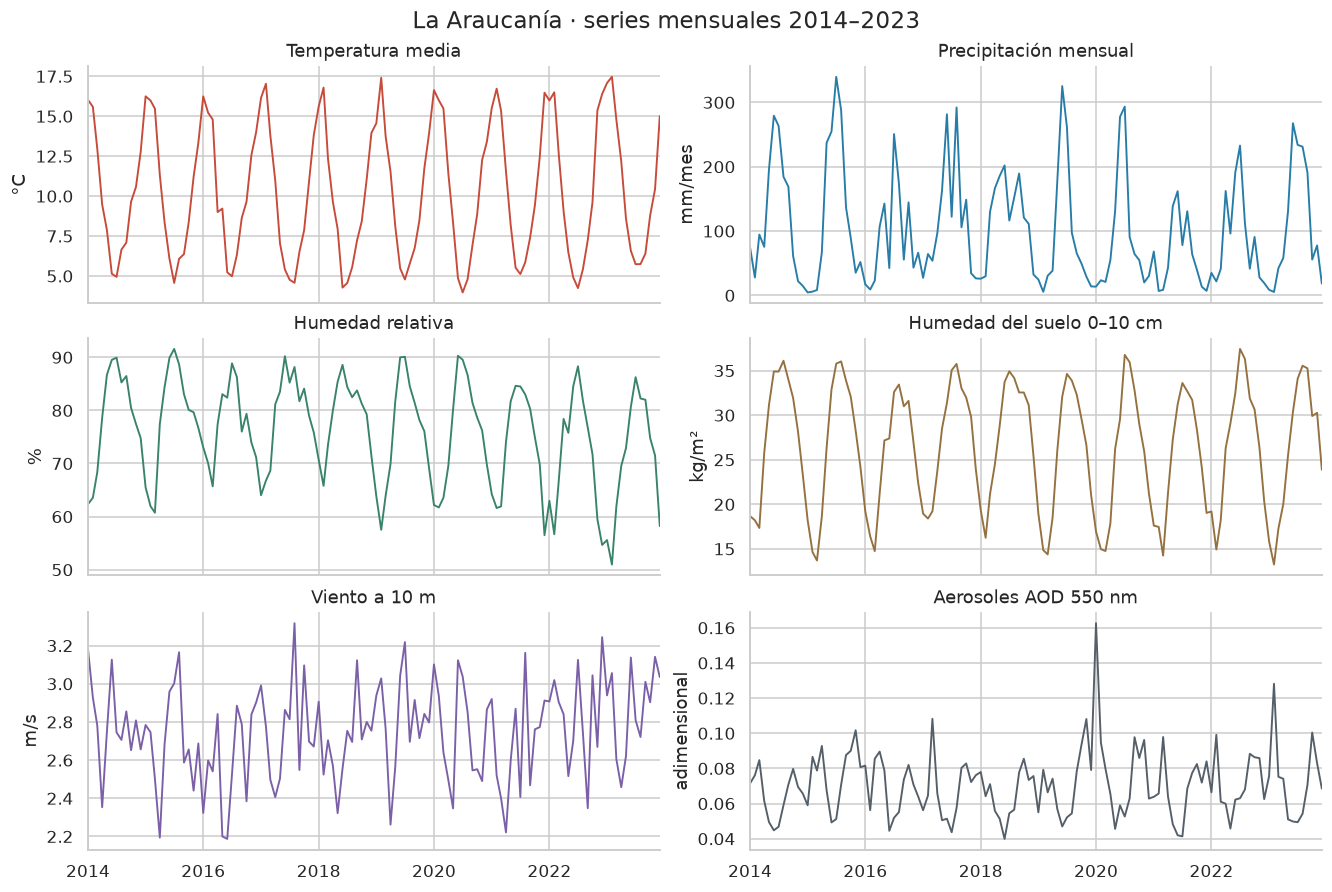

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, (variable, (title, unit, color)) in zip(axes.flat, CORE.items()):
    ax.plot(regional_eda.index, regional_eda[variable], color=color, linewidth=1.25)
    ax.set(title=title, ylabel=unit, xlim=(EXPECTED_MONTHS.min(), EXPECTED_MONTHS.max()))
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('La Araucanía · series mensuales 2014–2023', fontsize=15)
plt.show()

## 5. Ciclo anual y variabilidad entre años
Cada caja reúne diez observaciones del mismo mes calendario. La línea negra indica su promedio dentro de 2014–2023. Esta referencia describe nuestro período de estudio.

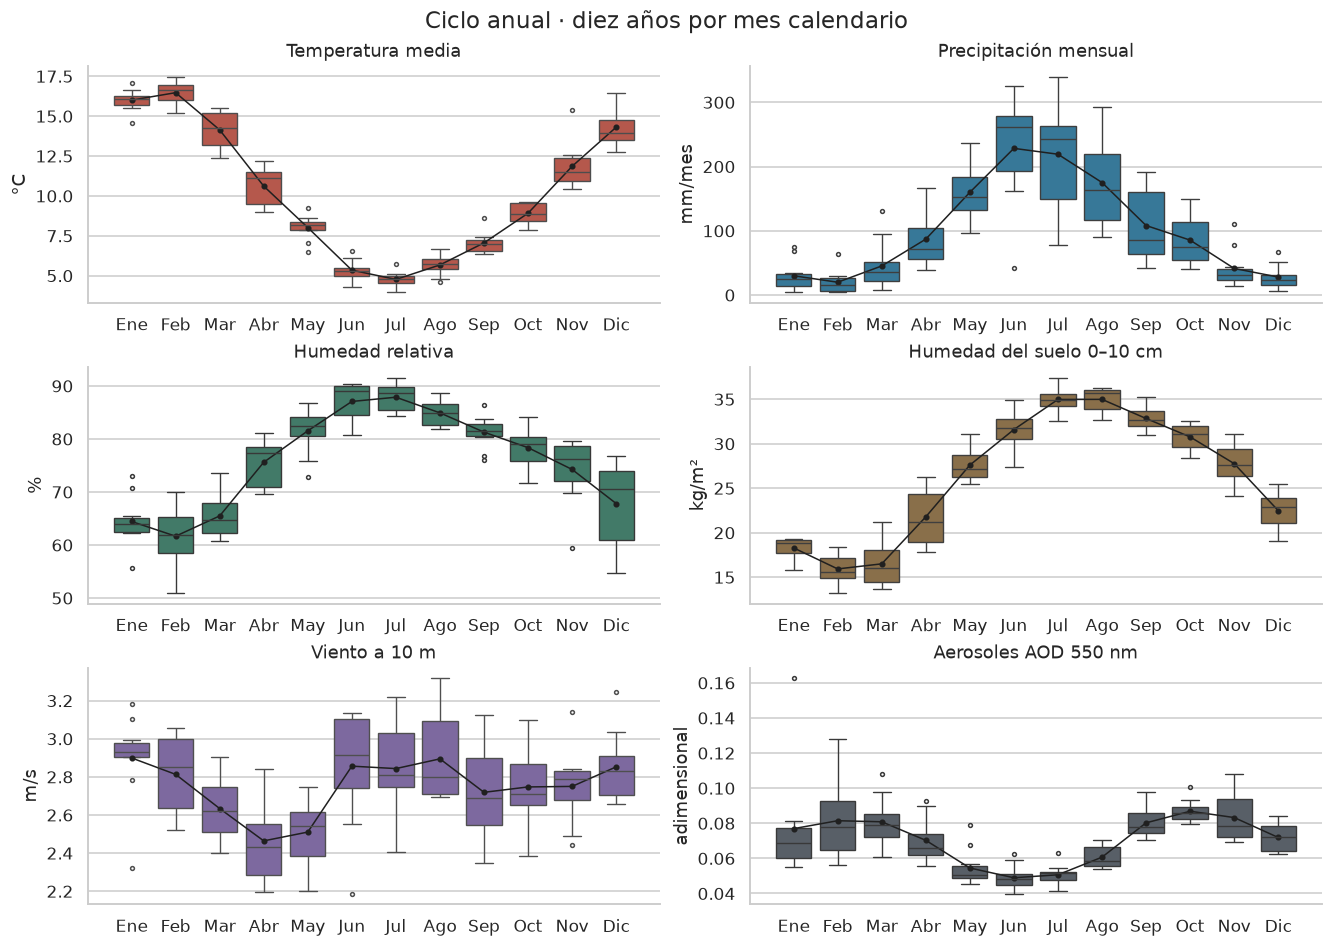

In [7]:
seasonal = regional_eda[list(CORE)].copy()
seasonal['calendar_month'] = seasonal.index.month
fig, axes = plt.subplots(3, 2, figsize=(12, 8.5), constrained_layout=True)
for ax, (variable, (title, unit, color)) in zip(axes.flat, CORE.items()):
    sns.boxplot(data=seasonal, x='calendar_month', y=variable, order=list(range(1, 13)), color=color, fliersize=2.5, linewidth=.9, ax=ax)
    averages = seasonal.groupby('calendar_month')[variable].mean().reindex(range(1, 13))
    ax.plot(np.arange(12), averages, '-o', color='#202020', linewidth=1, markersize=3)
    ax.set_xticks(range(12), MONTH_LABELS)
    ax.set(title=title, xlabel='', ylabel=unit)
fig.suptitle('Ciclo anual · diez años por mes calendario', fontsize=15)
plt.show()

## 6. Anomalías: separar la estación del año
Anomalía = valor observado − promedio del mismo mes durante 2014–2023. Así, enero se compara con otros eneros. Se usan diferencias en °C y mm, no una mezcla de unidades ni una conversión de meses a días.

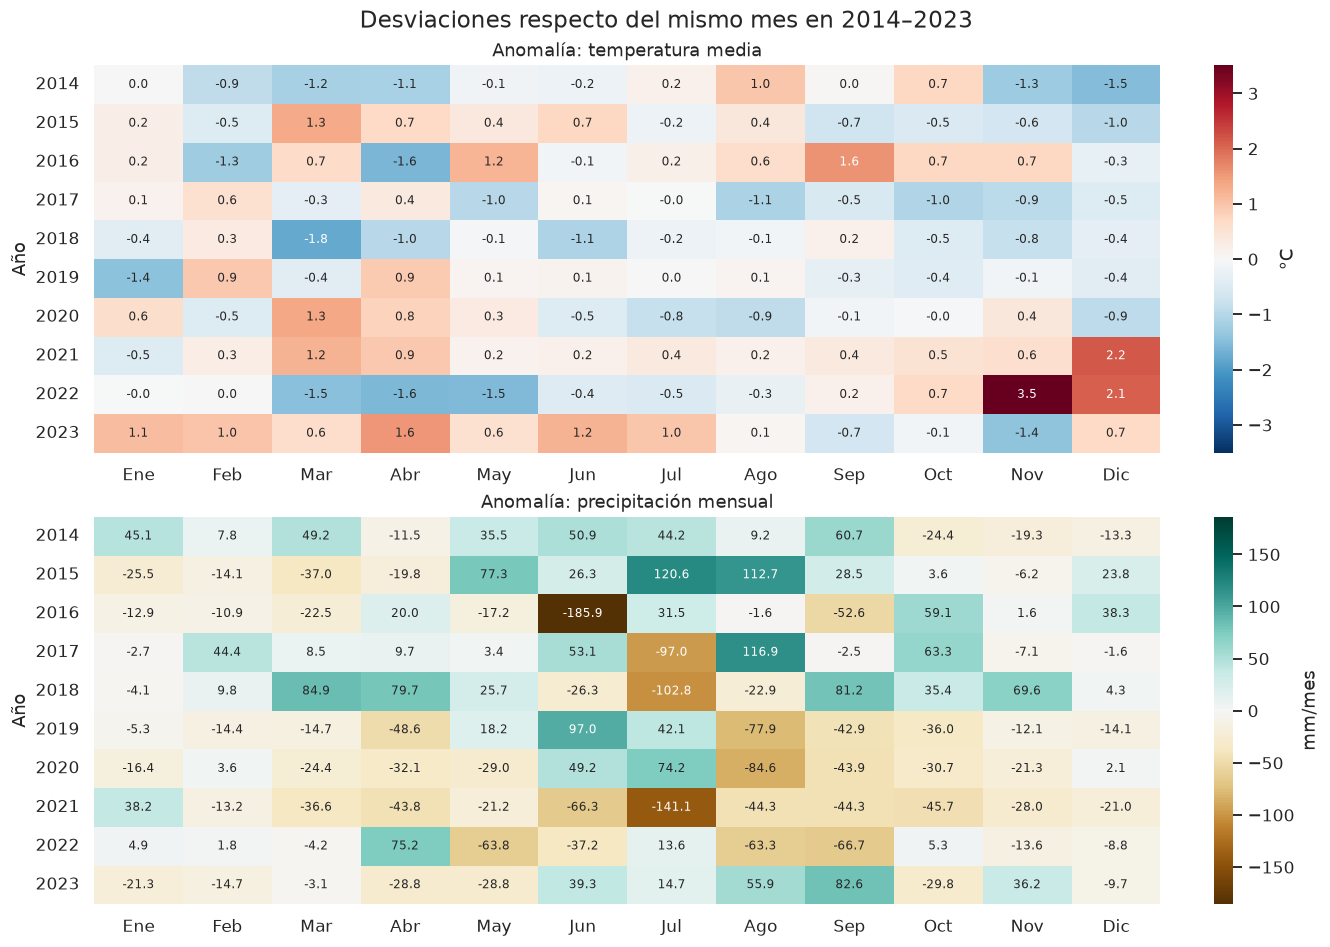

In [8]:
anomalies = regional_eda[list(CORE)] - regional_eda[list(CORE)].groupby(regional_eda.index.month).transform('mean')
assert np.allclose(anomalies.groupby(anomalies.index.month).mean(), 0, atol=1e-8)
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5), constrained_layout=True)
for ax, variable, palette in zip(axes, ['temperature_2m_c', 'precipitation_mm'], ['RdBu_r', 'BrBG']):
    data = anomalies[[variable]].assign(year=anomalies.index.year, month=anomalies.index.month)
    matrix = data.pivot(index='year', columns='month', values=variable)
    limit = max(float(np.nanmax(np.abs(matrix))), .01)
    sns.heatmap(matrix, ax=ax, cmap=palette, center=0, vmin=-limit, vmax=limit, annot=True, fmt='.1f', annot_kws={'fontsize': 8}, cbar_kws={'label': UNITS[variable]})
    ax.set_xticklabels(MONTH_LABELS, rotation=0)
    ax.set(title=f'Anomalía: {CORE[variable][0].lower()}', xlabel='', ylabel='Año')
fig.suptitle('Desviaciones respecto del mismo mes en 2014–2023', fontsize=15)
plt.show()

## 7. Comparación entre comunas
Promedios del período, calculados con las observaciones que cumplen cobertura. La matriz estandariza **cada variable entre comunas** para comparar perfiles sin mezclar unidades. El gris identifica suelo excluido por cobertura insuficiente.

Las comunas pueden compartir píxeles nativos. Estas diferencias no implican mediciones independientes a escala local ni permiten tratar las 3.840 filas como muestras espaciales independientes.

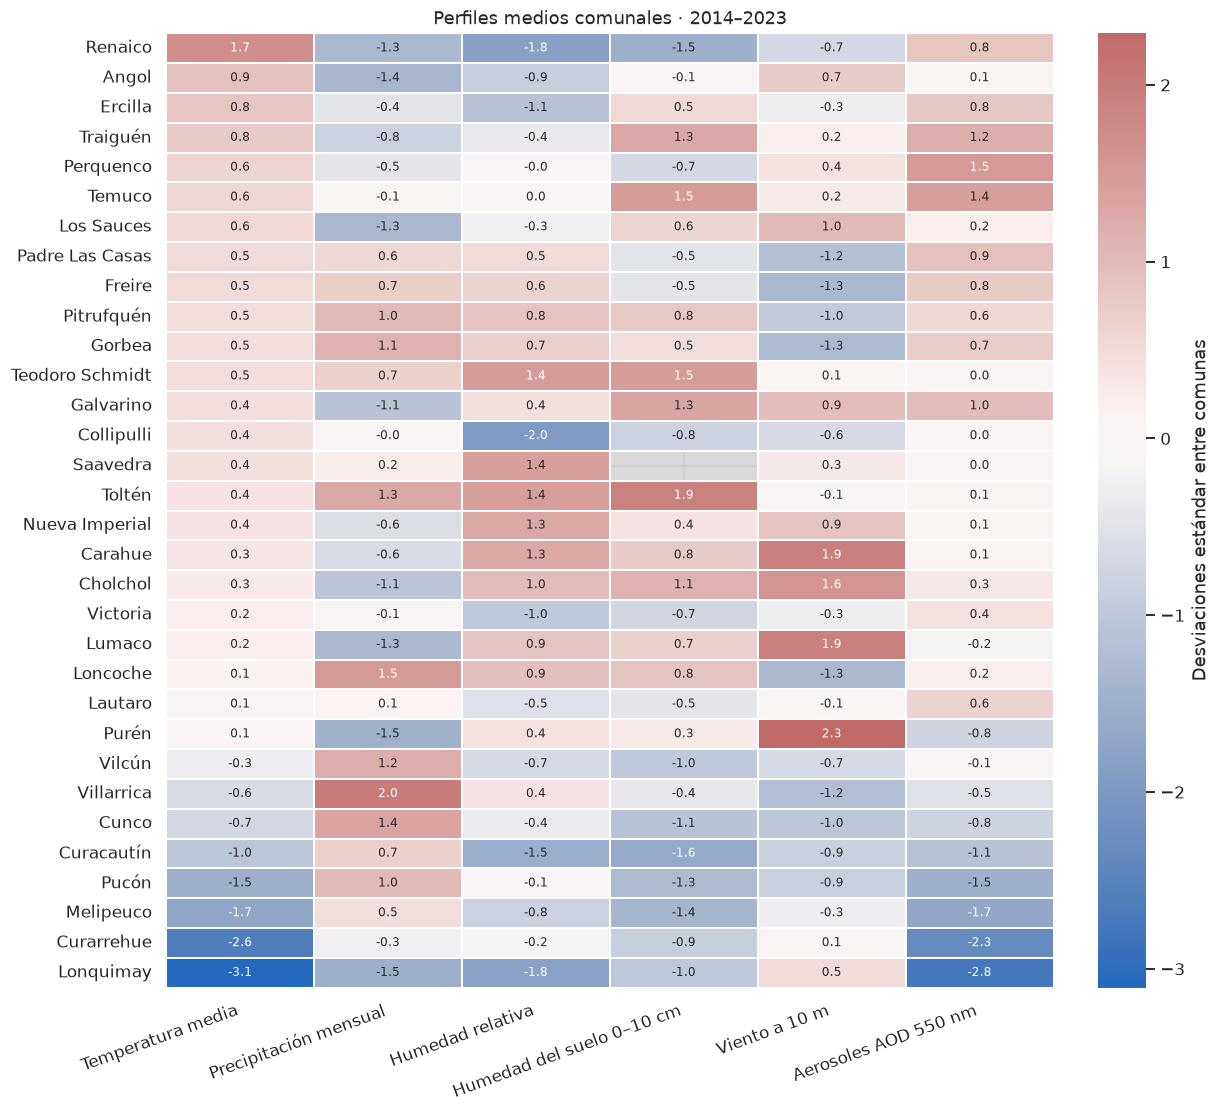

,temperature_2m_c,precipitation_mm,relative_humidity_2m_pct,soil_moisture_0_10cm_kgm2,wind_speed_10m_ms,aod_550
commune_name,,,,,,
Renaico,13.273,79.886,70.543,22.546,2.329,0.082
Angol,12.183,79.401,73.866,26.762,3.264,0.075
Ercilla,12.081,94.736,72.987,28.736,2.584,0.082
Traiguén,11.979,88.548,75.571,30.918,2.910,0.086
Perquenco,11.744,94.553,76.688,24.966,3.048,0.088
Temuco,11.730,101.268,76.914,31.501,2.940,0.088
Los Sauces,11.694,79.917,75.982,28.898,3.425,0.077
Padre Las Casas,11.621,112.017,78.478,25.708,2.008,0.083


In [9]:
profiles = communal_eda.groupby('commune_name', observed=True)[list(CORE)].mean()
profiles = profiles.sort_values('temperature_2m_c', ascending=False)
standardized = (profiles - profiles.mean()) / profiles.std(ddof=0).replace(0, np.nan)
palette = sns.color_palette('vlag', as_cmap=True)
fig, ax = plt.subplots(figsize=(11, 10), constrained_layout=True)
ax.set_facecolor('#D9D9D9')
sns.heatmap(standardized, cmap=palette, center=0, annot=True, fmt='.1f', annot_kws={'fontsize': 8}, linewidths=.25, ax=ax, cbar_kws={'label': 'Desviaciones estándar entre comunas'})
ax.set_xticklabels([CORE[v][0] for v in standardized.columns], rotation=20, ha='right')
ax.set(title='Perfiles medios comunales · 2014–2023', xlabel='', ylabel='')
plt.show()
display(profiles.round(3).head(8))

## 8. Relaciones exploratorias
Se compara la correlación de Spearman de las series mensuales con la de sus anomalías. Se calcula como correlación de rangos promedio, conservando los empates.

Son asociaciones descriptivas: hay autocorrelación temporal y fuentes de reanálisis compartidas. No se interpretan como causalidad, significación estadística independiente ni capacidad predictiva.

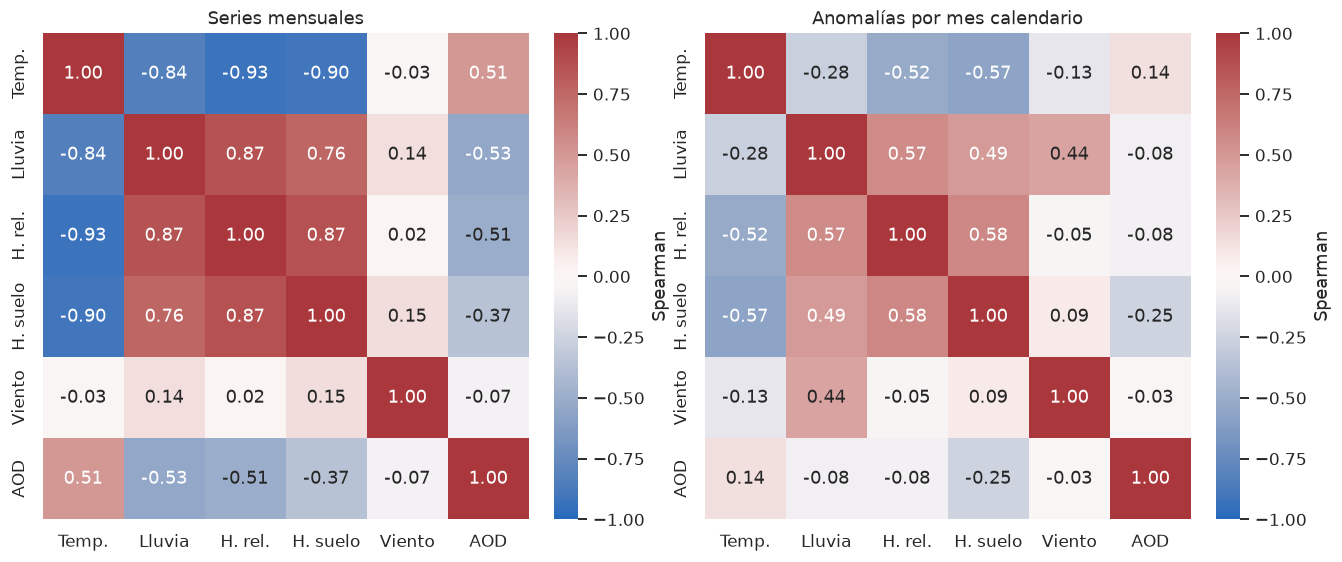

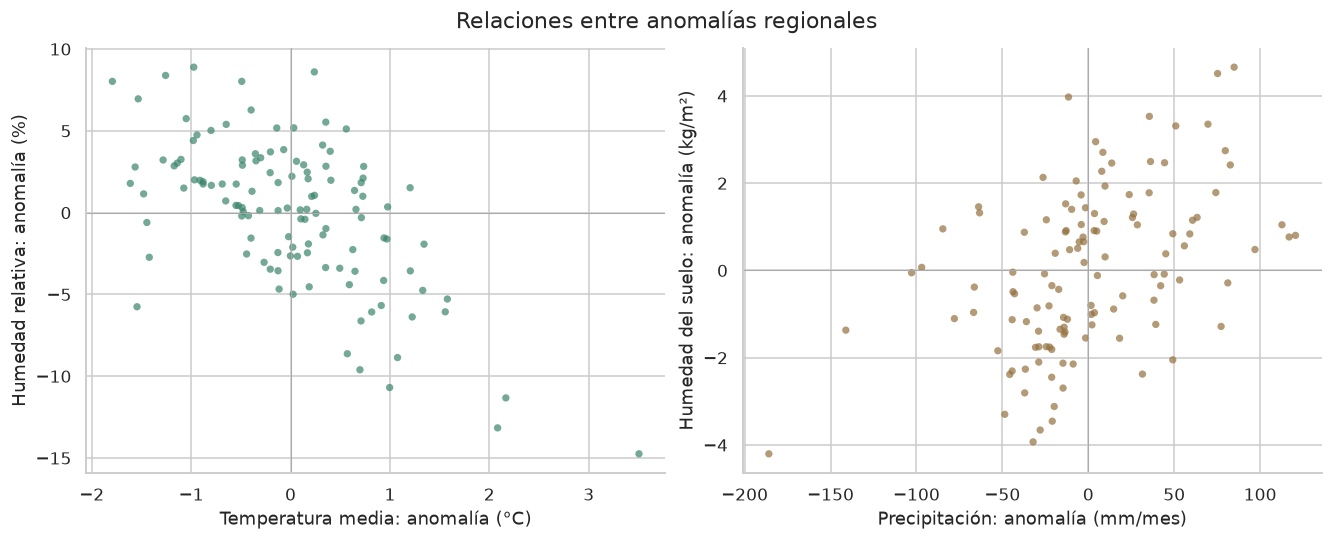

In [10]:
raw_corr = regional_eda[list(CORE)].rank().corr()
anomaly_corr = anomalies.rank().corr()
short_labels = ['Temp.', 'Lluvia', 'H. rel.', 'H. suelo', 'Viento', 'AOD']
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, matrix, title in zip(axes, [raw_corr, anomaly_corr], ['Series mensuales', 'Anomalías por mes calendario']):
    sns.heatmap(matrix, ax=ax, cmap='vlag', vmin=-1, vmax=1, center=0, square=True, annot=True, fmt='.2f', xticklabels=short_labels, yticklabels=short_labels, cbar_kws={'label': 'Spearman'})
    ax.set_title(title)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, x, y in [(axes[0], 'temperature_2m_c', 'relative_humidity_2m_pct'), (axes[1], 'precipitation_mm', 'soil_moisture_0_10cm_kgm2')]:
    ax.scatter(anomalies[x], anomalies[y], s=23, color=CORE[y][2], alpha=.7, edgecolors='none')
    ax.axhline(0, color='#AAAAAA', linewidth=.7)
    ax.axvline(0, color='#AAAAAA', linewidth=.7)
    short_names = {'temperature_2m_c': 'Temperatura media', 'relative_humidity_2m_pct': 'Humedad relativa', 'precipitation_mm': 'Precipitación', 'soil_moisture_0_10cm_kgm2': 'Humedad del suelo'}
    ax.set(xlabel=f'{short_names[x]}: anomalía ({UNITS[x]})', ylabel=f'{short_names[y]}: anomalía ({UNITS[y]})')
fig.suptitle('Relaciones entre anomalías regionales')
plt.show()

## 9. Hallazgos preliminares y próximos pasos
Los siguientes resúmenes se calculan desde las tablas; no se escriben conclusiones numéricas fijas. La referencia vial de 2019 se conserva separada y no se replica como una observación para cada mes.

La primera etapa describe exclusivamente los datos ambientales. Las secciones 11–15 amplían la exploración y verifican el calendario de CONAF antes de realizar el cruce regional.

La primera etapa describe exclusivamente los datos ambientales. Las secciones 11–15 amplían la exploración y verifican el calendario de CONAF antes de realizar el cruce regional.

In [11]:
annual = regional_eda.groupby(regional_eda.index.year).agg(
    temperature_mean_c=('temperature_2m_c', 'mean'),
    precipitation_total_mm=('precipitation_mm', 'sum'),
)
warmest_year = int(annual.temperature_mean_c.idxmax())
driest_year = int(annual.precipitation_total_mm.idxmin())
soil_low = coverage_by_commune.query('meses_con_cobertura_insuficiente > 0')
upper_pairs = anomaly_corr.where(np.triu(np.ones(anomaly_corr.shape), k=1).astype(bool)).stack()
strongest_pair = upper_pairs.abs().idxmax()
strongest_value = float(upper_pairs.loc[strongest_pair])
findings = {
    'warmest_year_in_this_period': warmest_year,
    'lowest_precipitation_year_in_this_period': driest_year,
    'strongest_anomaly_spearman_pair': list(strongest_pair),
    'strongest_anomaly_spearman_value': strongest_value,
}
display(annual.round(2))
display(Markdown(
    f'- Año con mayor temperatura media regional en esta ventana: **{warmest_year}**.\n'
    f'- Año con menor precipitación acumulada regional: **{driest_year}**.\n'
    f'- Comunas con cobertura de suelo inferior al {MIN_COVERAGE:g} %: **{len(soil_low)}**.\n'
    f'- Asociación más fuerte entre anomalías: **{CORE[strongest_pair[0]][0]} / {CORE[strongest_pair[1]][0]}**, Spearman **{strongest_value:.2f}**.\n'
    '- Los extremos se mantienen. Los diez años describen este período y no bastan por sí solos para atribuir cambios climáticos.'
))
display(roads[['geography_level', 'commune_id', 'name', 'reference_year', 'road_length_km']].head())

,temperature_mean_c,precipitation_total_mm
month,,
2014,9.89,1461.48
2015,10.28,1517.70
2016,10.49,1074.36
2017,9.90,1415.89
2018,9.78,1461.80
2019,10.19,1118.48
2020,10.25,1073.96
2021,10.79,760.01
2022,10.32,1070.56


- Año con mayor temperatura media regional en esta ventana: **2021**.
- Año con menor precipitación acumulada regional: **2021**.
- Comunas con cobertura de suelo inferior al 80 %: **1**.
- Asociación más fuerte entre anomalías: **Humedad relativa / Humedad del suelo 0–10 cm**, Spearman **0.58**.
- Los extremos se mantienen. Los diez años describen este período y no bastan por sí solos para atribuir cambios climáticos.

,geography_level,commune_id,name,reference_year,road_length_km
0,region,<NA>,La Araucanía,2019,13981.362
1,commune,09101,Temuco,2019,1022.347
2,commune,09102,Carahue,2019,550.867
3,commune,09103,Cunco,2019,545.301
4,commune,09104,Curarrehue,2019,226.944


## 10. Exportación y comprobación de los originales
Se guardan tres CSV limpios y un reporte JSON, con códigos como texto, unidades corregidas, fuentes verificadas y decisiones de limpieza. `soil_coverage_ok` permite aplicar otros umbrales posteriormente. Las mediciones originales se conservan, incluso las marcadas por baja cobertura.

In [12]:
OUTPUT.mkdir(exist_ok=True)
region.to_csv(OUTPUT / 'region_mensual_limpio.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m')
communes.to_csv(OUTPUT / 'comunas_mensual_limpio.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m')
roads.to_csv(OUTPUT / 'infraestructura_vial_limpia.csv', index=False, encoding='utf-8-sig')

report = {
    'scope': {'start': '2014-01', 'end': '2023-12', 'months': 120, 'communes': 32},
    'source_sha256': source_hashes,
    'all_checks_passed': bool(audit.resultado.eq('OK').all()),
    'checks': checks,
    'cleaning_log': cleaning_log,
    'units': UNITS,
    'measurement_values_changed': 0,
    'rows_removed': 0,
    'values_imputed': 0,
    'soil_coverage_threshold_pct': MIN_COVERAGE,
    'soil_rows_flagged_region': int((~region.soil_coverage_ok).sum()),
    'soil_rows_flagged_communes': int((~communes.soil_coverage_ok).sum()),
    'communes_with_low_soil_coverage': soil_low.reset_index().to_dict('records'),
    'regional_IQR_review_signals': extremes.to_dict('records'),
    'findings_descriptive_only': findings,
    'road_commune_id_missing_is_intentional_for_regional_row': True,
    'CONAF_join_performed_in_this_validation_stage': False,
    'additional_exploration_report': 'hallazgos_exploratorios.json',
    'outputs': {},
}
for path in [OUTPUT / name for name in ['comunas_mensual_limpio.csv', 'infraestructura_vial_limpia.csv', 'region_mensual_limpio.csv']]:
    report['outputs'][path.name] = {'rows': int(len(pd.read_csv(path))), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
assert source_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}, 'Un original cambió durante el análisis.'
(OUTPUT / 'reporte_validacion.json').write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Validación ambiental completada; originales intactos. Salidas en:', OUTPUT.relative_to(ROOT))
display(pd.DataFrame([{'archivo': p.name, 'KB': round(p.stat().st_size / 1024, 1)} for p in sorted(OUTPUT.iterdir()) if p.is_file()]))

Validación ambiental completada; originales intactos. Salidas en: datos_mensuales_2014_2023\limpios


,archivo,KB
0,comunas_mensual_limpio.csv,595.6
1,hallazgos_exploratorios.json,85.3
2,incendios_contexto_mensual.csv,89.5
3,infraestructura_vial_limpia.csv,3.5
4,modelo_conaf_binomial_negativa.csv,0.9
5,region_mensual_limpio.csv,18.9
6,reporte_validacion.json,16.3


## 11. Persistencia y desfase: salir del ciclo estacional
**Pregunta:** ¿aparecen episodios prolongados más cálidos y con menos agua que lo habitual para su propio mes?

Usamos anomalías respecto de enero–diciembre de **2014–2023**, no una normal climática de largo plazo. Una racha exige lluvia y humedad superficial del suelo inferiores a sus respectivos promedios del mismo mes; contamos además los meses con temperatura superior a ese promedio. No es un índice de riesgo ni una definición de sequía meteorológica. Comparamos la duración con una referencia basada en la mediana para mostrar su sensibilidad.

**Desfase:** comparamos lluvia del mes `t − k` con suelo del mes `t`, para `k = 0…3`. Las correlaciones utilizan pares completos y ordenados. El rango al retirar un año se calcula excluyendo pares con cualquiera de sus dos fechas en ese año y recalculando la referencia mensual sin él. Es sensibilidad descriptiva, no un intervalo de confianza. La autocorrelación puede sostener las asociaciones y no permite atribuir causalidad.

,start,end,months,also_warmer_months,rain_anomaly_sum_mm,mean_soil_anomaly_kgm2
0,2021-03,2021-12,10,10,-492.432,-1.778
1,2019-08,2020-01,6,2,-199.541,-1.124
2,2015-01,2015-04,4,3,-96.391,-1.826
3,2022-11,2023-02,4,4,-58.384,-2.175
4,2019-02,2019-04,3,2,-77.808,-2.166
5,2020-03,2020-05,3,3,-85.511,-2.357


,lag_months,n_pairs,spearman,omit_year_min,omit_year_max
0,0,120,0.487,0.459,0.534
1,1,119,0.530,0.477,0.604
2,2,118,0.425,0.388,0.503
3,3,117,0.392,0.349,0.450


- Racha más larga con ambos indicadores bajo su media mensual: **2021-03 a 2021-12**, **10 meses**; los 10 fueron también más cálidos que su referencia.
- Con la mediana, la racha más larga es **2021-06 a 2021-12 (7 meses)**. El episodio es visible, pero su duración depende del umbral.
- El mayor coeficiente entre los cuatro desfases no demuestra un tiempo físico exacto de respuesta: los valores son próximos y el suelo conserva persistencia entre meses.

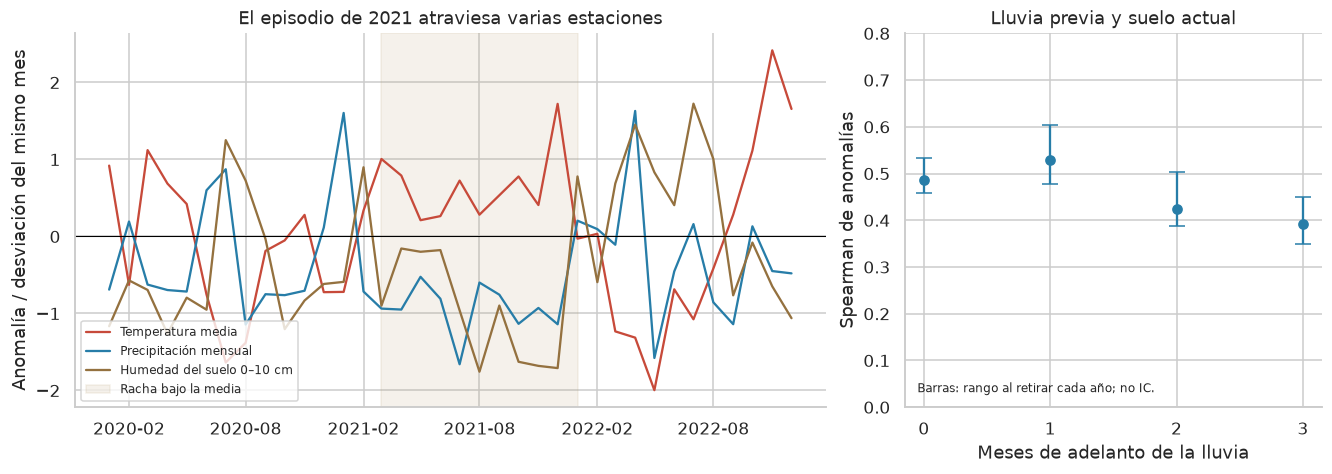

In [13]:
T, P, S = 'temperature_2m_c', 'precipitation_mm', 'soil_moisture_0_10cm_kgm2'

def spearman_pair(x, y):
    pair = pd.concat([x.rename('x'), y.rename('y')], axis=1).dropna()
    return float(pair.rank().corr().iloc[0, 1]), len(pair)

def describe_runs(anomaly_frame):
    mask = anomaly_frame[P].lt(0) & anomaly_frame[S].lt(0)
    records = []
    for _, run in mask.groupby(mask.ne(mask.shift()).cumsum()):
        if not bool(run.iloc[0]):
            continue
        segment = anomaly_frame.loc[run.index]
        records.append({
            'start': run.index[0].strftime('%Y-%m'),
            'end': run.index[-1].strftime('%Y-%m'),
            'months': int(len(run)),
            'also_warmer_months': int(segment[T].gt(0).sum()),
            'rain_anomaly_sum_mm': float(segment[P].sum()),
            'mean_soil_anomaly_kgm2': float(segment[S].mean()),
        })
    return pd.DataFrame(records).sort_values(['months', 'start'], ascending=[False, True]).reset_index(drop=True)

dry_runs = describe_runs(anomalies)
median_anomalies = regional_eda[list(CORE)] - regional_eda[list(CORE)].groupby(regional_eda.index.month).transform('median')
median_runs = describe_runs(median_anomalies)
lag_records = []
for lag in range(4):
    rho, n = spearman_pair(anomalies[P].shift(lag), anomalies[S])
    sensitivities = []
    for omitted in range(2014, 2024):
        reference = regional_eda.loc[regional_eda.index.year != omitted, [P, S]]
        reference_mean = reference.groupby(reference.index.month).mean()
        adjusted = regional_eda[[P, S]] - reference_mean.reindex(regional_eda.index.month).set_axis(regional_eda.index)
        rain_date = adjusted.index - pd.DateOffset(months=lag)
        pairs_valid = (adjusted.index.year != omitted) & (rain_date.year != omitted)
        value, _ = spearman_pair(adjusted[P].shift(lag).where(pairs_valid), adjusted[S].where(pairs_valid))
        sensitivities.append(value)
    lag_records.append({'lag_months': lag, 'n_pairs': n, 'spearman': rho,
                        'omit_year_min': min(sensitivities), 'omit_year_max': max(sensitivities)})
lag_table = pd.DataFrame(lag_records)
display(dry_runs.head(6).round(3))
display(lag_table.round(3))
longest = dry_runs.iloc[0]
longest_median = median_runs.iloc[0]
display(Markdown(
    f"- Racha más larga con ambos indicadores bajo su media mensual: **{longest['start']} a {longest['end']}**, "
    f"**{int(longest['months'])} meses**; los {int(longest['also_warmer_months'])} fueron también más cálidos que su referencia.\n"
    f"- Con la mediana, la racha más larga es **{longest_median['start']} a {longest_median['end']} "
    f"({int(longest_median['months'])} meses)**. El episodio es visible, pero su duración depende del umbral.\n"
    '- El mayor coeficiente entre los cuatro desfases no demuestra un tiempo físico exacto de respuesta: '
    'los valores son próximos y el suelo conserva persistencia entre meses.'
))

monthly_std = regional_eda[list(CORE)].groupby(regional_eda.index.month).transform('std')
standard_anomalies = anomalies.div(monthly_std.replace(0, np.nan))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1.8, 1]})
for variable in [T, P, S]:
    axes[0].plot(standard_anomalies.loc['2020':'2022'].index,
                 standard_anomalies.loc['2020':'2022', variable],
                 color=CORE[variable][2], label=CORE[variable][0], linewidth=1.5)
axes[0].axhline(0, color='black', linewidth=.7)
axes[0].axvspan(pd.Timestamp(longest['start']), pd.Timestamp(longest['end']) + pd.offsets.MonthBegin(1),
               color='#BCA579', alpha=.15, label='Racha bajo la media')
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[0].set(title='El episodio de 2021 atraviesa varias estaciones', ylabel='Anomalía / desviación del mismo mes')
axes[0].legend(fontsize=8, loc='lower left')
axes[1].errorbar(lag_table.lag_months, lag_table.spearman,
                 yerr=np.vstack([lag_table.spearman-lag_table.omit_year_min,
                                 lag_table.omit_year_max-lag_table.spearman]),
                 fmt='o', color='#277DA8', capsize=5)
axes[1].set(xticks=range(4), ylim=(0, .8), xlabel='Meses de adelanto de la lluvia',
            ylabel='Spearman de anomalías', title='Lluvia previa y suelo actual')
axes[1].text(.03, .04, 'Barras: rango al retirar cada año; no IC.',
             transform=axes[1].transAxes, fontsize=8)
plt.show()

## 12. ¿Son episodios regionales o dependen de unas pocas comunas?
Comparamos cada comuna con **su propia referencia**, en vez de confundir su clima habitual con una anomalía. Seleccionamos de forma reproducible el año con menor lluvia regional y el mes con mayor anomalía térmica regional. Son casos exploratorios escogidos tras observar la serie, no pruebas independientes.

El primer panel muestra el porcentaje de diferencia de la lluvia anual respecto de la media anual 2014–2023 de esa comuna. El segundo muestra la temperatura media mensual respecto de los diez valores del mismo mes en esa comuna. Los porcentajes de comunas describen extensión administrativa, no porcentaje de superficie ni réplicas independientes: varias comunas comparten píxeles nativos. Se excluye el suelo de Saavedra por cobertura insuficiente.

- En **2021**, la lluvia regional fue **-38.1 %** respecto de la media del período. Las **32/32 comunas** tuvieron menos lluvia, con diferencias entre **-44.8 % y -32.0 %**.
- La anomalía media anual del suelo fue negativa en **31/31** comunas con cobertura suficiente.
- En **2022-11**, las **32/32 comunas** fueron más cálidas que su referencia del mismo mes, entre **+2.32 y +4.06 °C**. Son promedios mensuales modelados; no son máximas diarias ni identifican por sí solos una ola de calor.

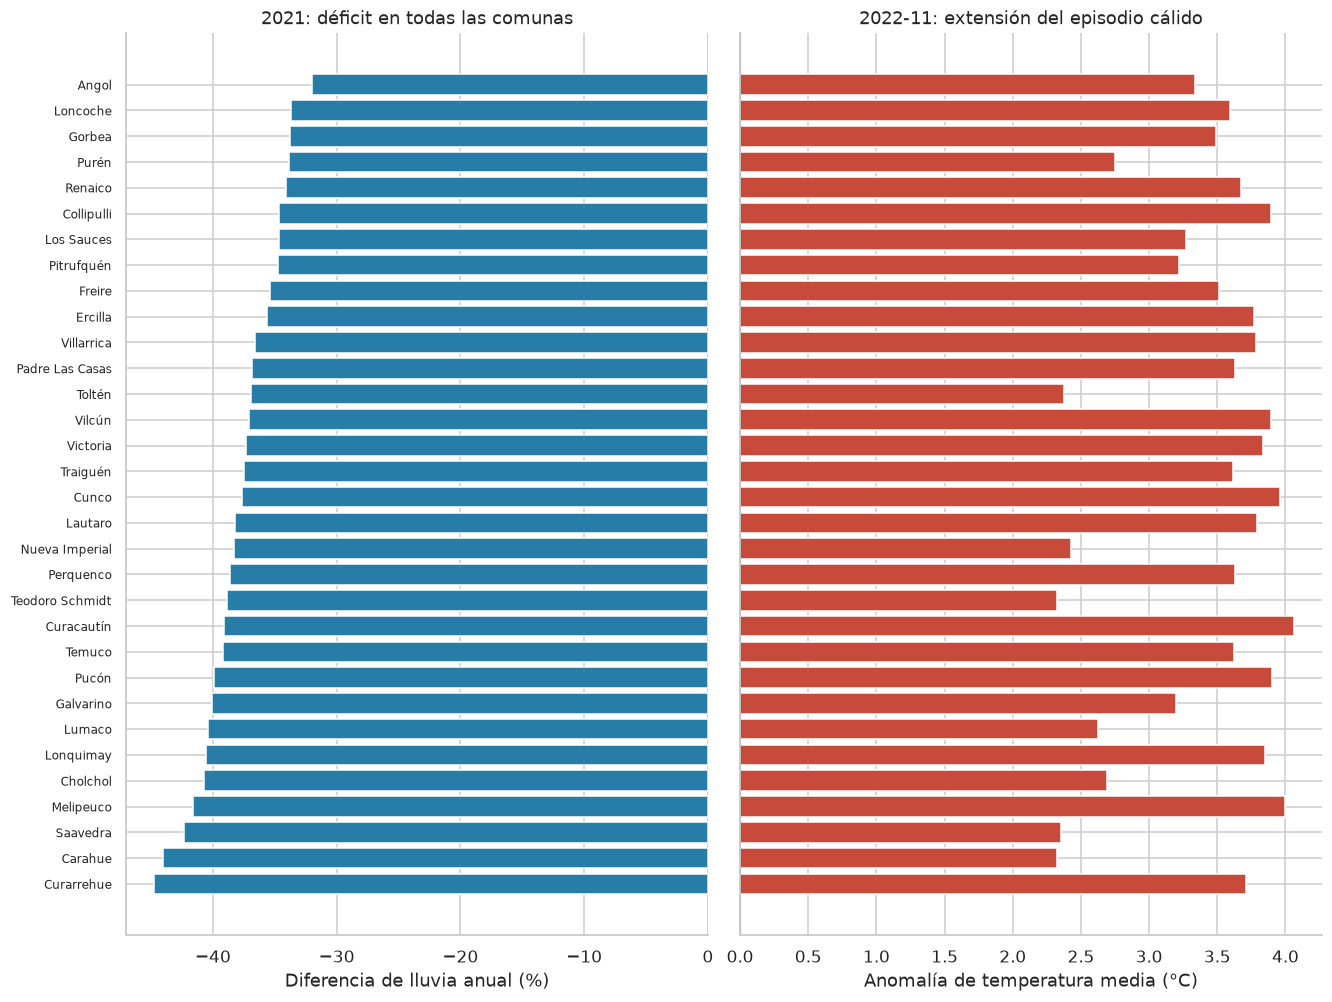

In [14]:
commune_columns = [T, P, S]
commune_anomalies = communal_eda[['month', 'commune_id', 'commune_name']].copy()
commune_anomalies[commune_columns] = (
    communal_eda[commune_columns]
    - communal_eda.groupby(['commune_id', communal_eda.month.dt.month])[commune_columns].transform('mean')
)
annual_rain_commune = communal_eda.groupby(['commune_id', communal_eda.month.dt.year])[P].sum().unstack()
case_year = int(annual.precipitation_total_mm.idxmin())
case_month = anomalies[T].idxmax()
rain_difference = (annual_rain_commune[case_year] / annual_rain_commune.mean(axis=1) - 1) * 100
names = communal_eda.drop_duplicates('commune_id').set_index('commune_id').commune_name
spatial_cases = pd.DataFrame({'commune_name': names, 'rain_difference_pct': rain_difference})
temperature_case = commune_anomalies.loc[commune_anomalies.month.eq(case_month)].set_index('commune_id')[T]
spatial_cases['temperature_anomaly_c'] = temperature_case
soil_case = commune_anomalies.loc[commune_anomalies.month.dt.year.eq(case_year)].groupby('commune_id')[S].mean()
spatial_cases['soil_year_mean_anomaly_kgm2'] = soil_case
spatial_cases = spatial_cases.sort_values('rain_difference_pct')
regional_rain_difference = float((annual.loc[case_year, 'precipitation_total_mm'] / annual.precipitation_total_mm.mean() - 1) * 100)
display(Markdown(
    f"- En **{case_year}**, la lluvia regional fue **{regional_rain_difference:.1f} %** respecto de la media del período. "
    f"Las **{int(spatial_cases.rain_difference_pct.lt(0).sum())}/{len(spatial_cases)} comunas** tuvieron menos lluvia, "
    f"con diferencias entre **{rain_difference.min():.1f} % y {rain_difference.max():.1f} %**.\n"
    f"- La anomalía media anual del suelo fue negativa en **{int(soil_case.lt(0).sum())}/{int(soil_case.notna().sum())}** comunas con cobertura suficiente.\n"
    f"- En **{case_month:%Y-%m}**, las **{int(temperature_case.gt(0).sum())}/{temperature_case.notna().sum()} comunas** fueron más cálidas "
    f"que su referencia del mismo mes, entre **+{temperature_case.min():.2f} y +{temperature_case.max():.2f} °C**. "
    'Son promedios mensuales modelados; no son máximas diarias ni identifican por sí solos una ola de calor.'
))
fig, axes = plt.subplots(1, 2, figsize=(12, 9), sharey=True, constrained_layout=True)
y = np.arange(len(spatial_cases))
axes[0].barh(y, spatial_cases.rain_difference_pct, color='#277DA8')
axes[1].barh(y, spatial_cases.temperature_anomaly_c, color='#C74A3A')
axes[0].set(yticks=y, yticklabels=spatial_cases.commune_name, xlabel='Diferencia de lluvia anual (%)',
            title=f'{case_year}: déficit en todas las comunas')
axes[1].set(xlabel='Anomalía de temperatura media (°C)', title=f'{case_month:%Y-%m}: extensión del episodio cálido')
for ax in axes:
    ax.axvline(0, color='black', linewidth=.7)
    ax.tick_params(axis='y', labelsize=8)
plt.show()

## 13. CONAF: reconstruir fechas y verificar qué se está contando
Los CSV locales son `data/conaf/conaf.csv` (región × mes) y `conaf_comuna.csv` (comuna × temporada, columna `numero_incendios`). Se verifica que sus totales regionales y comunales coincidan en todas las temporadas; analizamos **cantidad de incendios registrados**, no hectáreas quemadas ni gravedad.

El calendario de temporada de CONAF va de julio a junio ([documentación oficial](https://www.conafprevencionincendios.cl/situacion-nacional-de-incendios-forestales/)). Por eso, `ENERO` de `2014-2015` se convierte en `2015-01`, usando `temporada`, sin tratar `año` como año calendario. La región es `IX`, verificada también en el archivo comunal. Los archivos locales no contienen un enlace al documento original ni fecha de descarga: esta limitación de procedencia queda registrada; la documentación respalda el calendario, no autentica cada cifra del CSV.

Se hace una unión interna por mes sin inventar ceros. El comunal solo se usa aquí para conciliación de totales; no se reparten sus incendios por mes. El reporte de validación de la sección 10 describe la primera etapa ambiental; el nuevo JSON de la sección 15 documenta este cruce por separado.

In [15]:
conaf_paths = [ROOT / 'data/conaf/conaf.csv', ROOT / 'data/conaf/conaf_comuna.csv']
conaf_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in conaf_paths}
fire_raw = pd.read_csv(conaf_paths[0])
fire_communes = pd.read_csv(conaf_paths[1])
span = fire_raw.temporada.str.extract(r'^(\d{4})-(\d{4})$').astype(int)
assert span[1].eq(span[0] + 1).all(), 'Temporadas mal formadas'
month_numbers = {name: i for i, name in enumerate(
    ['ENERO','FEBRERO','MARZO','ABRIL','MAYO','JUNIO','JULIO','AGOSTO','SEPTIEMBRE','OCTUBRE','NOVIEMBRE','DICIEMBRE'], 1)}
calendar_month = fire_raw.mes.str.strip().str.upper().map(month_numbers)
assert calendar_month.notna().all(), 'Mes CONAF no reconocido'
calendar_year = span[0] + calendar_month.lt(7).astype(int)
fire_raw['month'] = pd.to_datetime(dict(year=calendar_year, month=calendar_month, day=1))
assert not fire_raw.month.duplicated().any()
assert fire_raw.groupby('temporada').size().eq(12).all()
assert fire_communes.region.eq('IX').all()
assert not fire_communes.duplicated(['temporada', 'comuna']).any()
assert fire_communes.groupby('temporada').comuna.nunique().eq(32).all()
for values in [fire_raw['IX'], fire_communes.numero_incendios]:
    assert values.notna().all() and values.ge(0).all() and values.mod(1).eq(0).all()
season_totals = pd.concat([
    fire_raw.groupby('temporada')['IX'].sum().rename('regional_count'),
    fire_communes.groupby('temporada').numero_incendios.sum().rename('communal_count')], axis=1)
assert season_totals.notna().all().all()
assert season_totals.regional_count.eq(season_totals.communal_count).all()
fire_monthly = fire_raw.set_index('month')['IX'].sort_index().astype(int).rename('fire_count')
assert fire_monthly.index.equals(pd.date_range(fire_monthly.index.min(), fire_monthly.index.max(), freq='MS', name='month'))
joint = regional_eda[list(CORE)].join(fire_monthly, how='inner')
weather_without_fire = regional_eda.index.difference(fire_monthly.index)
fire_outside_weather = fire_monthly.index.difference(regional_eda.index)
assert len(joint) == 114 and len(weather_without_fire) == 6 and len(fire_outside_weather) == 6
assert joint.notna().all().all()
display(season_totals)
display(Markdown(
    f"**Coincidencia temporal: {len(joint)} meses, {joint.index.min():%Y-%m} a {joint.index.max():%Y-%m}.** "
    f"Faltan registros CONAF para {weather_without_fire.min():%Y-%m} a {weather_without_fire.max():%Y-%m}; "
    f"se excluyen {len(fire_outside_weather)} meses de CONAF posteriores a diciembre de 2023. "
    'Los totales por temporada coinciden entre ambos CSV en las diez temporadas.'
))

,regional_count,communal_count
temporada,,
2014-2015,1496.0,1496.0
2015-2016,1344.0,1344.0
2016-2017,753.0,753.0
2017-2018,969.0,969.0
2018-2019,1352.0,1352.0
2019-2020,1802.0,1802.0
2020-2021,1367.0,1367.0
2021-2022,1457.0,1457.0
2022-2023,1753.0,1753.0


**Coincidencia temporal: 114 meses, 2014-07 a 2023-12.** Faltan registros CONAF para 2014-01 a 2014-06; se excluyen 6 meses de CONAF posteriores a diciembre de 2023. Los totales por temporada coinciden entre ambos CSV en las diez temporadas.

## 14. Incendios y ambiente después de descontar el mes del año
**Pregunta:** dentro de meses comparables, ¿más calor, menos agua, viento o aerosoles acompañan más incendios registrados?

Recalculamos todas las referencias sobre los **mismos 114 meses**. Comparamos tres descripciones: Spearman de anomalías respecto de la media del mes; su rango al retirar cada año y recalcular las referencias; y correlación de rangos percentiles calculados **dentro de cada mes calendario**. Esta última evita que los meses con mayor variabilidad absoluta dominen por su escala. Sus valores no son idénticos a un Spearman global ni están sujetos a la misma ponderación por magnitud.

No se calculan pruebas de significancia ni se selecciona un predictor. Los meses tienen dependencia temporal; los métodos se usan como controles de sensibilidad y no como validación causal. Un viento mensual con asociación pequeña no descarta el efecto de ráfagas durante un incendio. AOD mide extinción óptica por aerosoles: no identifica por sí solo humo, origen local ni superficie quemada.

,label,n_months,anomaly_spearman,omit_year_min,omit_year_max,within_month_rank_correlation
variable,,,,,,
temperature_2m_c,Temperatura media,114,0.359,0.273,0.438,0.226
precipitation_mm,Precipitación mensual,114,-0.529,-0.555,-0.503,-0.631
relative_humidity_2m_pct,Humedad relativa,114,-0.539,-0.601,-0.438,-0.525
soil_moisture_0_10cm_kgm2,Humedad del suelo 0–10 cm,114,-0.630,-0.696,-0.565,-0.519
wind_speed_10m_ms,Viento a 10 m,114,-0.008,-0.016,0.037,0.066
aod_550,Aerosoles AOD 550 nm,114,0.293,0.205,0.390,0.119


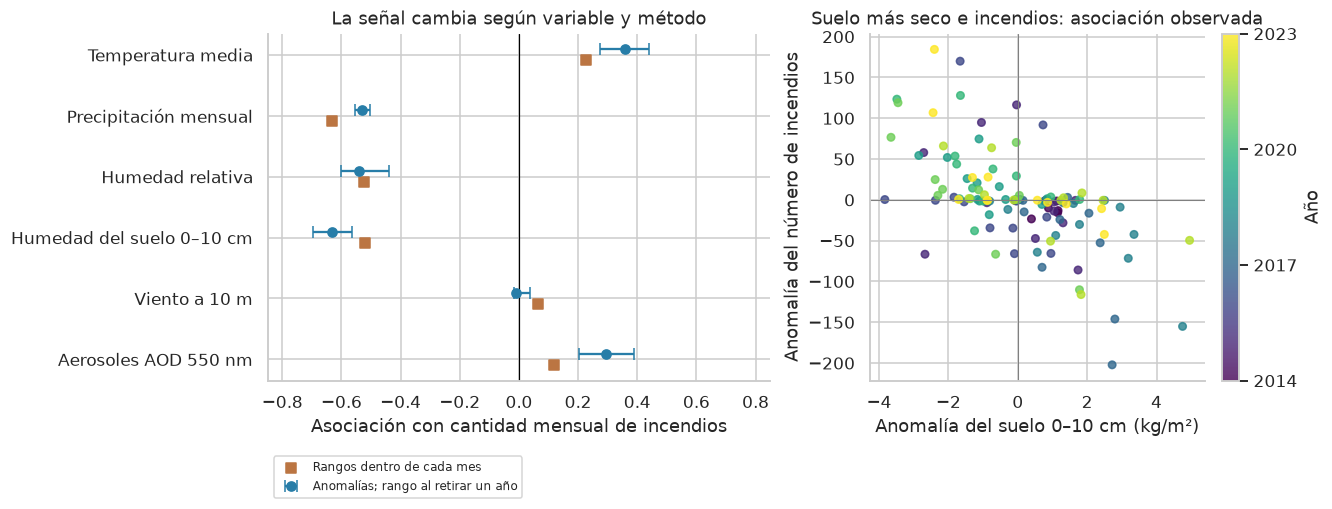

,aod_550,fire_count,aod_anomaly,fire_anomaly
month,,,,
2020-01-01,0.163,319,0.085,14.333
2023-02-01,0.128,459,0.046,106.778
2017-03-01,0.108,157,0.028,-146.111
2019-11-01,0.108,159,0.025,74.600
2015-11-01,0.102,37,0.018,-47.400


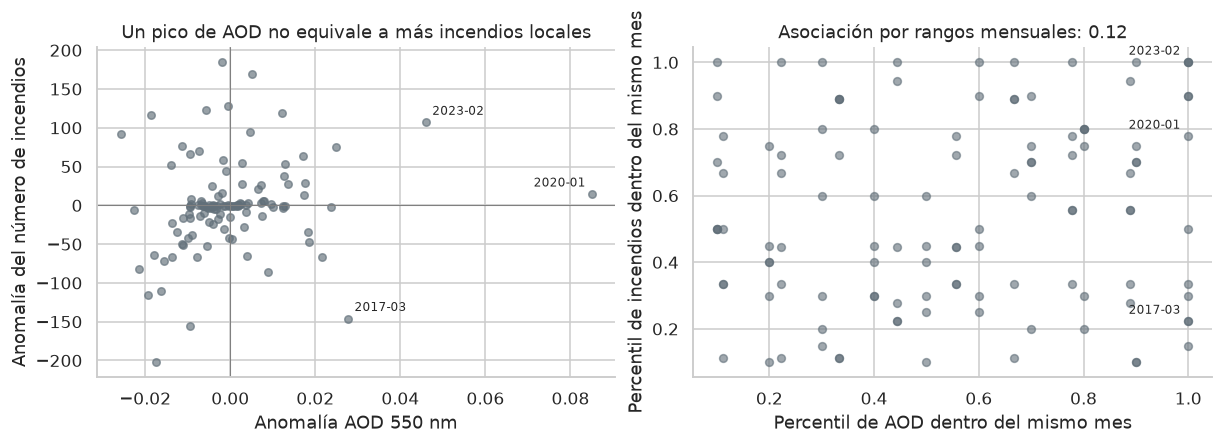

In [16]:
joint_anomalies = joint - joint.groupby(joint.index.month).transform('mean')
within_month_ranks = joint.groupby(joint.index.month).rank(pct=True)
fire_association_records = []
for variable in CORE:
    rho, n = spearman_pair(joint_anomalies[variable], joint_anomalies.fire_count)
    sensitivity = []
    for omitted in sorted(joint.index.year.unique()):
        reduced = joint.loc[joint.index.year != omitted]
        reduced_anomaly = reduced - reduced.groupby(reduced.index.month).transform('mean')
        value, _ = spearman_pair(reduced_anomaly[variable], reduced_anomaly.fire_count)
        sensitivity.append(value)
    fire_association_records.append({
        'variable': variable, 'label': CORE[variable][0], 'n_months': n,
        'anomaly_spearman': rho, 'omit_year_min': min(sensitivity), 'omit_year_max': max(sensitivity),
        'within_month_rank_correlation': float(within_month_ranks[variable].corr(within_month_ranks.fire_count)),
    })
fire_associations = pd.DataFrame(fire_association_records).set_index('variable')
display(fire_associations.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1.5, 1]})
y = np.arange(len(fire_associations))
values = fire_associations.anomaly_spearman
axes[0].errorbar(values, y-.09,
    xerr=np.vstack([values-fire_associations.omit_year_min, fire_associations.omit_year_max-values]),
    fmt='o', color='#277DA8', capsize=4, label='Anomalías; rango al retirar un año')
axes[0].scatter(fire_associations.within_month_rank_correlation, y+.09, color='#BB7542',
                marker='s', label='Rangos dentro de cada mes')
axes[0].axvline(0, color='black', linewidth=.8)
axes[0].set(yticks=y, yticklabels=fire_associations.label, xlim=(-.85, .85),
            xlabel='Asociación con cantidad mensual de incendios', title='La señal cambia según variable y método')
axes[0].invert_yaxis()
axes[0].legend(loc='upper left', bbox_to_anchor=(0, -.20), fontsize=8)
scatter = axes[1].scatter(joint_anomalies[S], joint_anomalies.fire_count,
                         c=joint.index.year, cmap='viridis', s=24, alpha=.8)
axes[1].axhline(0, color='gray', linewidth=.7)
axes[1].axvline(0, color='gray', linewidth=.7)
axes[1].set(xlabel='Anomalía del suelo 0–10 cm (kg/m²)', ylabel='Anomalía del número de incendios',
            title='Suelo más seco e incendios: asociación observada')
fig.colorbar(scatter, ax=axes[1], label='Año', ticks=[2014,2017,2020,2023])
plt.show()

# Contrastar los mayores picos de AOD con el número de incendios realmente observado.
aod_cases = joint.nlargest(5, 'aod_550')[['aod_550', 'fire_count']].copy()
aod_cases['aod_anomaly'] = joint_anomalies.loc[aod_cases.index, 'aod_550']
aod_cases['fire_anomaly'] = joint_anomalies.loc[aod_cases.index, 'fire_count']
display(aod_cases.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].scatter(joint_anomalies.aod_550, joint_anomalies.fire_count, s=24, color='#616F79', alpha=.65)
for date in aod_cases.index[:3]:
    axes[0].annotate(date.strftime('%Y-%m'),
        (joint_anomalies.loc[date, 'aod_550'], joint_anomalies.loc[date, 'fire_count']),
        xytext=(-4 if date == aod_cases.index[0] else 4, 5), textcoords='offset points',
        ha='right' if date == aod_cases.index[0] else 'left', fontsize=8)
axes[0].set(xlabel='Anomalía AOD 550 nm', ylabel='Anomalía del número de incendios',
            title='Un pico de AOD no equivale a más incendios locales')
axes[0].axhline(0, color='gray', linewidth=.7)
axes[0].axvline(0, color='gray', linewidth=.7)
axes[1].scatter(within_month_ranks.aod_550, within_month_ranks.fire_count,
                s=26, alpha=.6, color='#616F79')
for date in aod_cases.index[:3]:
    axes[1].annotate(date.strftime('%Y-%m'),
        (within_month_ranks.loc[date, 'aod_550'], within_month_ranks.loc[date, 'fire_count']),
        xytext=(-5, 5), textcoords='offset points', ha='right', fontsize=8)
axes[1].set(xlabel='Percentil de AOD dentro del mismo mes',
            ylabel='Percentil de incendios dentro del mismo mes',
            title=f'Asociación por rangos mensuales: {fire_associations.loc["aod_550", "within_month_rank_correlation"]:.2f}')
plt.show()

## 15. Hallazgos que merecen seguimiento y límites
Esta exploración conserva los originales, evita duplicar descargas y guarda **un único JSON pequeño** con fechas, métodos y resultados. Los análisis son descriptivos dentro de 2014–2023; no producen pronósticos, puntuaciones de riesgo ni atribuciones de causa. Los siguientes puntos se recalculan al ejecutar el notebook.

In [17]:
soil_result = fire_associations.loc[S]
rain_result = fire_associations.loc[P]
aod_result = fire_associations.loc['aod_550']
wind_result = fire_associations.loc['wind_speed_10m_ms']
top_aod_month = aod_cases.index[0]
display(Markdown(
    f"1. **Persistencia y extensión:** {case_year} fue el año de menor lluvia de esta ventana; "
    'el déficit aparece en todas las comunas, junto con suelo más seco en todas las que tienen cobertura suficiente. '
    'La racha mensual de menor agua se mantiene entre estaciones, aunque cambia al usar media o mediana.\n'
    f"2. **Agua e incendios:** las asociaciones con anomalías del suelo (**{soil_result.anomaly_spearman:.2f}**) "
    f"y de lluvia (**{rain_result.anomaly_spearman:.2f}**) conservan signo negativo al retirar cada año. "
    'El orden de sus intensidades cambia con los rangos mensuales; no hay una variable ganadora demostrada.\n'
    f"3. **Una anomalía cálida compartida:** {case_month:%Y-%m} presenta calentamiento respecto de su propio mes en todas las comunas. "
    'Se puede estudiar como episodio, sin confundirlo con el verano ni con una tendencia de largo plazo.\n'
    f"4. **AOD requiere cautela:** la asociación con incendios baja de **{aod_result.anomaly_spearman:.2f}** "
    f"a **{aod_result.within_month_rank_correlation:.2f}** al comparar posiciones dentro del mes. "
    f"El mayor AOD fue {top_aod_month:%Y-%m}, con **{int(joint.loc[top_aod_month,'fire_count'])} incendios**, "
    f"solo **{joint_anomalies.loc[top_aod_month,'fire_count']:+.1f}** respecto de la referencia de ese mes. "
    'No demuestra origen del aerosol.\n'
    f"5. **El viento medio mensual aporta poca asociación en esta escala** "
    f"({wind_result.anomaly_spearman:.2f}); no responde a la pregunta sobre ráfagas, propagación o daño.\n\n"
    'Las secciones siguientes contrastan presencia y alta actividad, además de meses discordantes '
    '(poco suelo húmedo sin aumento de incendios, o muchos incendios sin gran anomalía térmica). '
    'Para estudiar gravedad haría falta superficie quemada; estos conteos no la sustituyen.'
))

exploration_report = {
    'scope': {'environmental_months': 120, 'communes': 32, 'reference': '2014-01/2023-12',
              'fire_matched_months': len(joint), 'fire_start': joint.index.min().strftime('%Y-%m'),
              'fire_end': joint.index.max().strftime('%Y-%m')},
    'source_sha256': {**source_hashes, **conaf_hashes},
    'calendar_documentation': 'https://www.conafprevencionincendios.cl/situacion-nacional-de-incendios-forestales/',
    'conaf_original_download_reference': 'No consta en los CSV locales; calendario documentado y totales conciliados, cifras sin autenticación externa adicional.',
    'conaf_variable': 'Cantidad de incendios registrados; no superficie quemada.',
    'weather_months_without_fire': weather_without_fire.strftime('%Y-%m').tolist(),
    'fire_months_excluded_after_2023': fire_outside_weather.strftime('%Y-%m').tolist(),
    'seasonal_totals_reconciled': season_totals.reset_index().to_dict('records'),
    'runs_below_monthly_mean': dry_runs.to_dict('records'),
    'runs_below_monthly_median': median_runs.to_dict('records'),
    'rain_to_soil_lags': lag_table.to_dict('records'),
    'spatial_cases': {'driest_regional_year': case_year, 'warmest_anomaly_month': case_month.strftime('%Y-%m'),
                      'regional_rain_difference_pct': regional_rain_difference,
                      'communes': json.loads(spatial_cases.reset_index().to_json(orient='records'))},
    'fire_associations': fire_associations.reset_index().to_dict('records'),
    'aod_case_studies': aod_cases.reset_index().assign(month=lambda x:x.month.dt.strftime('%Y-%m')).to_dict('records'),
    'methods': {
        'anomaly': 'Observed minus calendar-month mean; 120 environmental months or 114 jointly matched months as appropriate.',
        'lag': 'Rain at t-k versus soil at t. Paired dates excluded when either falls in the omitted year; baseline recomputed without that year.',
        'omit_year_range': 'Sensitivity only, not a confidence interval or statistical significance test.',
        'within_month_rank': 'Pearson correlation of percent ranks calculated separately within each calendar month.',
        'spatial': 'Commune own baseline; soil masked below 80% coverage. Counts of communes are not independent pixels nor area fractions.',
    },
    'limitations': ['Ten-year descriptive baseline, not a long-term climate normal.',
                    'Temporal autocorrelation and shared source grids; no causal interpretation.',
                    'Cases selected after examining these same data.',
                    'Monthly environmental means cannot resolve daily fire weather.',
                    'Fire counts do not measure burned area or severity; AOD does not identify smoke origin.'],
}
assert source_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
assert conaf_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in conaf_paths}
exploration_path = OUTPUT / 'hallazgos_exploratorios.json'
exploration_path.write_text(json.dumps(exploration_report, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Análisis reproducible guardado:', exploration_path.relative_to(ROOT))
print('Fuentes originales sin cambios. Sin imputaciones, predicciones ni nuevas descargas.')

1. **Persistencia y extensión:** 2021 fue el año de menor lluvia de esta ventana; el déficit aparece en todas las comunas, junto con suelo más seco en todas las que tienen cobertura suficiente. La racha mensual de menor agua se mantiene entre estaciones, aunque cambia al usar media o mediana.
2. **Agua e incendios:** las asociaciones con anomalías del suelo (**-0.63**) y de lluvia (**-0.53**) conservan signo negativo al retirar cada año. El orden de sus intensidades cambia con los rangos mensuales; no hay una variable ganadora demostrada.
3. **Una anomalía cálida compartida:** 2022-11 presenta calentamiento respecto de su propio mes en todas las comunas. Se puede estudiar como episodio, sin confundirlo con el verano ni con una tendencia de largo plazo.
4. **AOD requiere cautela:** la asociación con incendios baja de **0.29** a **0.12** al comparar posiciones dentro del mes. El mayor AOD fue 2020-01, con **319 incendios**, solo **+14.3** respecto de la referencia de ese mes. No demuestra origen del aerosol.
5. **El viento medio mensual aporta poca asociación en esta escala** (-0.01); no responde a la pregunta sobre ráfagas, propagación o daño.

Las secciones siguientes contrastan presencia y alta actividad, además de meses discordantes (poco suelo húmedo sin aumento de incendios, o muchos incendios sin gran anomalía térmica). Para estudiar gravedad haría falta superficie quemada; estos conteos no la sustituyen.

Análisis reproducible guardado: datos_mensuales_2014_2023\limpios\hallazgos_exploratorios.json
Fuentes originales sin cambios. Sin imputaciones, predicciones ni nuevas descargas.


## 16. Cuándo hubo incendios registrados por CONAF
**Unidad de observación:** un mes en toda La Araucanía. `has_recorded_fire = fire_count > 0` identifica meses con al menos un incendio registrado; cero significa cero en el CSV, no ausencia demostrada de cualquier fuego. La celda anterior concilia estos conteos con los totales comunales de CONAF.

No conocemos el día de inicio, las coordenadas, la duración ni la superficie de cada incendio. Por tanto, describimos **condiciones del mes en que hubo incendios**, no el tiempo meteorológico en el instante del evento. El mapa muestra el conteo real; gris representa falta de datos, nunca cero imputado.

,calendar_month,observed_months,with_recorded_fire,without_recorded_fire,fire_count_min,fire_count_max
month,,,,,,
1,Ene,9,9,0,222,489
2,Feb,9,9,0,150,459
3,Mar,9,9,0,148,473
4,Abr,9,9,0,23,218
5,May,9,8,1,0,13
6,Jun,9,4,5,0,2
7,Jul,10,5,5,0,2
8,Ago,10,8,2,0,8
9,Sep,10,9,1,0,45


**100/114 meses con incendios registrados**, y **14 meses con cero registros**. Solo May, Jun, Jul, Ago, Sep permiten comparar presencia y cero dentro del mismo mes. No se puede deducir qué diferencia enero con incendios de enero sin incendios: no hay en esta serie ningún enero con cero.

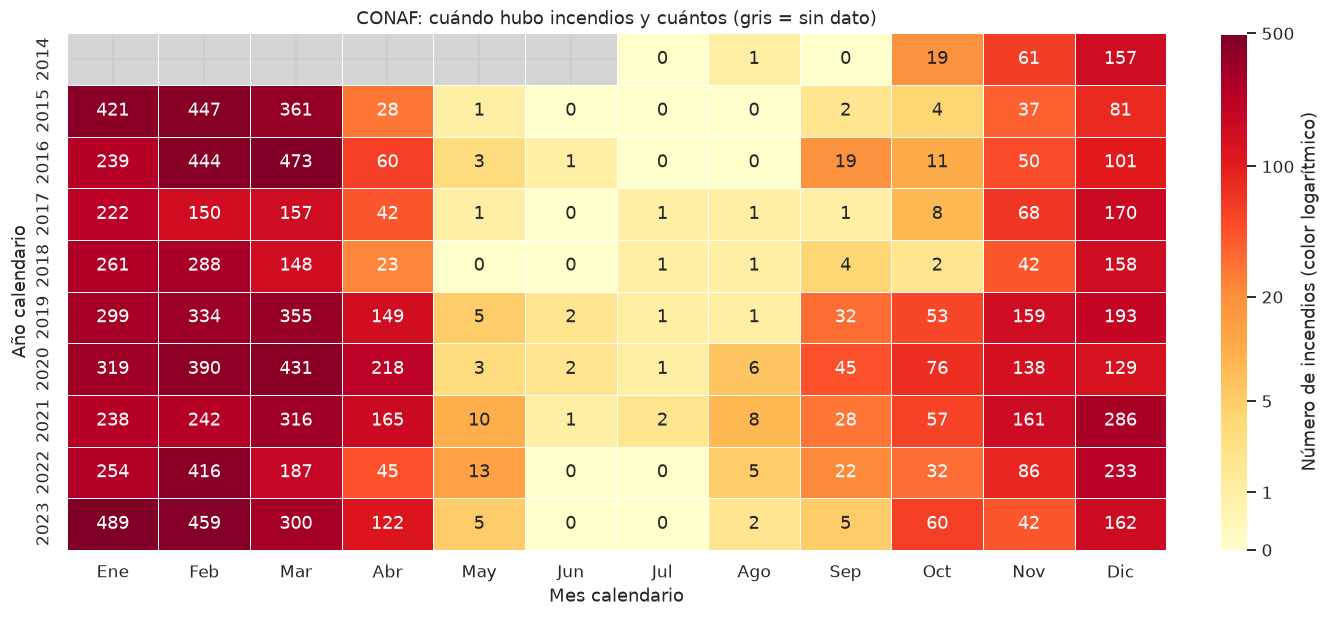

In [18]:
joint['has_recorded_fire'] = joint.fire_count.gt(0)
presence_calendar = joint.groupby(joint.index.month).agg(
    observed_months=('fire_count', 'size'),
    with_recorded_fire=('has_recorded_fire', 'sum'),
    fire_count_min=('fire_count', 'min'),
    fire_count_max=('fire_count', 'max'),
)
presence_calendar['without_recorded_fire'] = presence_calendar.observed_months - presence_calendar.with_recorded_fire
presence_calendar['calendar_month'] = [MONTH_LABELS[i-1] for i in presence_calendar.index]
mixed_calendar_months = presence_calendar.index[
    presence_calendar.with_recorded_fire.gt(0) & presence_calendar.without_recorded_fire.gt(0)].tolist()
supported_calendar_months = presence_calendar.index[
    presence_calendar.with_recorded_fire.ge(2) & presence_calendar.without_recorded_fire.ge(2)].tolist()
always_fire_calendar_months = presence_calendar.index[presence_calendar.without_recorded_fire.eq(0)].tolist()
assert len(joint) == 114
assert int(joint.has_recorded_fire.sum()) == 100
assert int((~joint.has_recorded_fire).sum()) == 14
display(presence_calendar[['calendar_month', 'observed_months', 'with_recorded_fire',
                           'without_recorded_fire', 'fire_count_min', 'fire_count_max']])
display(Markdown(
    f"**{int(joint.has_recorded_fire.sum())}/{len(joint)} meses con incendios registrados**, "
    f"y **{int((~joint.has_recorded_fire).sum())} meses con cero registros**. "
    f"Solo {', '.join(MONTH_LABELS[m-1] for m in mixed_calendar_months)} permiten comparar presencia y cero dentro del mismo mes. "
    'No se puede deducir qué diferencia enero con incendios de enero sin incendios: no hay en esta serie ningún enero con cero.'
))
fire_calendar = joint.fire_count.to_frame().assign(year=joint.index.year, calendar_month=joint.index.month)
fire_calendar = fire_calendar.pivot(index='year', columns='calendar_month', values='fire_count').reindex(
    index=range(2014, 2024), columns=range(1, 13))
fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
ax.set_facecolor('#D5D5D5')
sns.heatmap(np.log1p(fire_calendar), mask=fire_calendar.isna(), annot=fire_calendar,
            fmt='.0f', cmap='YlOrRd', linewidths=.5, linecolor='white',
            xticklabels=MONTH_LABELS, cbar_kws={'label': 'Número de incendios (color logarítmico)'}, ax=ax)
colorbar = ax.collections[0].colorbar
count_ticks = np.array([0, 1, 5, 20, 100, 500])
colorbar.set_ticks(np.log1p(count_ticks))
colorbar.set_ticklabels(count_ticks)
ax.set(xlabel='Mes calendario', ylabel='Año calendario',
        title='CONAF: cuándo hubo incendios y cuántos (gris = sin dato)')
ax.tick_params(axis='x', rotation=0)
plt.show()

## 17. Qué cambia entre meses con incendios y meses con cero registros
Comparamos **mayo con mayo, junio con junio, etc.**, utilizando solo los cinco meses calendario donde existen ambos grupos. Para cada variable calculamos la diferencia de medias entre grupos en cada mes calendario; después promediamos esas cinco diferencias, con igual peso por mes. La tabla conserva unidades físicas.

Como mayo y septiembre solo tienen un mes con cero registros, añadimos un control que exige **al menos dos observaciones por grupo**: junio, julio y agosto. Este control cambia la población comparada; no es una estimación del efecto causal del incendio. Las diferencias estandarizadas del gráfico dividen por la desviación de cada mes calendario antes de promediar. No se eliminan extremos ni se imputan datos.

,label,unit,mean_within_month_difference,n_positive,n_reference,supported_months_difference
variable,,,,,,
temperature_2m_c,Temperatura media,°C,-0.2047,34,14,-0.3605
precipitation_mm,Precipitación mensual,mm/mes,-59.5178,34,14,-65.6156
relative_humidity_2m_pct,Humedad relativa,%,-3.2232,34,14,-1.7928
soil_moisture_0_10cm_kgm2,Humedad del suelo 0–10 cm,kg/m²,-0.9687,34,14,-0.5868
wind_speed_10m_ms,Viento a 10 m,m/s,-0.0332,34,14,-0.0655
aod_550,Aerosoles AOD 550 nm,adimensional,0.0012,34,14,-0.0029


La comparación principal utiliza **34 meses con incendios y 14 con cero registros**. El control más exigente utiliza **17 y 12**, respectivamente.

- Los meses con incendios tienen, en promedio entre meses comparables, **-59.5 mm** de lluvia y **-0.97 kg/m²** de humedad del suelo respecto de los meses con cero.
- La diferencia térmica es **-0.20 °C**. Esta comparación de meses de transición e invierno no respalda que la sola presencia de incendios requiera un mes más cálido. Tampoco describe las condiciones de ignición de cada evento.
- La lluvia mantiene su diferencia negativa en el control con más observaciones por grupo; AOD cambia de signo y el contraste de suelo se atenúa. La muestra sin incendios es pequeña.

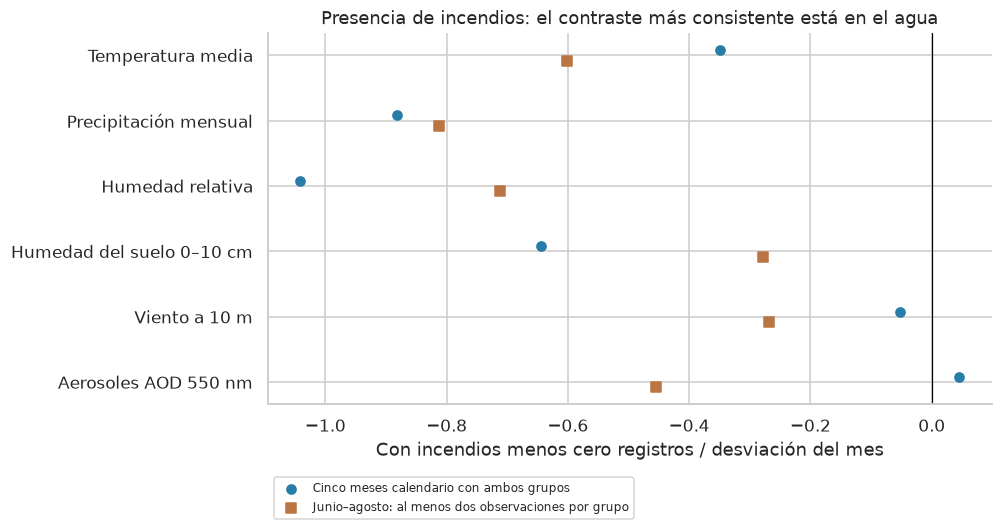

In [19]:
def monthly_group_contrast(features, group, eligible_months, variable_catalog=CORE):
    records = []
    for variable, description in variable_catalog.items():
        raw_differences, standardized_differences = [], []
        n_positive = n_reference = 0
        for calendar_month in eligible_months:
            x = features.loc[features.index.month == calendar_month, variable]
            labels = group.reindex(x.index)
            valid = x.notna() & labels.notna()
            x, labels = x.loc[valid], labels.loc[valid].astype(bool)
            assert labels.any() and (~labels).any()
            difference = float(x.loc[labels].mean() - x.loc[~labels].mean())
            raw_differences.append(difference)
            sd = float(x.std())
            standardized_differences.append(difference / sd if sd > 0 else np.nan)
            n_positive += int(labels.sum())
            n_reference += int((~labels).sum())
        records.append({'variable': variable, 'label': description[0], 'unit': description[1],
                        'calendar_months_compared': len(eligible_months),
                        'n_positive': n_positive, 'n_reference': n_reference,
                        'mean_within_month_difference': float(np.mean(raw_differences)),
                        'standardized_difference': float(np.nanmean(standardized_differences))})
    return pd.DataFrame(records).set_index('variable')

presence_contrast = monthly_group_contrast(joint[list(CORE)], joint.has_recorded_fire, mixed_calendar_months)
supported_presence_contrast = monthly_group_contrast(joint[list(CORE)], joint.has_recorded_fire, supported_calendar_months)
presence_comparison = presence_contrast[['label','unit','mean_within_month_difference','n_positive','n_reference']].copy()
presence_comparison['supported_months_difference'] = supported_presence_contrast.mean_within_month_difference
display(presence_comparison.round(4))
display(Markdown(
    f"La comparación principal utiliza **{int(presence_contrast.n_positive.iloc[0])} meses con incendios y "
    f"{int(presence_contrast.n_reference.iloc[0])} con cero registros**. "
    f"El control más exigente utiliza **{int(supported_presence_contrast.n_positive.iloc[0])} y "
    f"{int(supported_presence_contrast.n_reference.iloc[0])}**, respectivamente.\n\n"
    f"- Los meses con incendios tienen, en promedio entre meses comparables, **{presence_contrast.loc[P,'mean_within_month_difference']:.1f} mm** "
    f"de lluvia y **{presence_contrast.loc[S,'mean_within_month_difference']:.2f} kg/m²** de humedad del suelo respecto de los meses con cero.\n"
    f"- La diferencia térmica es **{presence_contrast.loc[T,'mean_within_month_difference']:+.2f} °C**. "
    'Esta comparación de meses de transición e invierno no respalda que la sola presencia de incendios requiera un mes más cálido. '
    'Tampoco describe las condiciones de ignición de cada evento.\n'
    '- La lluvia mantiene su diferencia negativa en el control con más observaciones por grupo; '
    'AOD cambia de signo y el contraste de suelo se atenúa. La muestra sin incendios es pequeña.'
))
fig, ax = plt.subplots(figsize=(9, 4.7), constrained_layout=True)
y = np.arange(len(CORE))
ax.scatter(presence_contrast.standardized_difference, y-.08, marker='o', color='#277DA8',
            label='Cinco meses calendario con ambos grupos')
ax.scatter(supported_presence_contrast.standardized_difference, y+.08, marker='s', color='#BB7542',
            label='Junio–agosto: al menos dos observaciones por grupo')
ax.axvline(0, color='black', linewidth=.8)
ax.set(yticks=y, yticklabels=presence_contrast.label,
        xlabel='Con incendios menos cero registros / desviación del mes',
        title='Presencia de incendios: el contraste más consistente está en el agua')
ax.invert_yaxis()
ax.legend(loc='upper left', bbox_to_anchor=(0, -.18), fontsize=8)
plt.show()

## 18. Cuando ya hay incendios: meses de alta actividad y condiciones previas
Entre enero–abril y octubre–diciembre hay incendios registrados en todos los años observados. En estos meses, la presencia por sí sola no distingue situaciones. Definimos **alta actividad** como conteo igual o superior al percentil 75 de su propio mes calendario; el resto de observaciones de esos mismos meses también tiene incendios. El umbral se calcula únicamente con conteos CONAF, sin seleccionar por clima.

Contrastamos ambos grupos dentro de cada mes y promediamos las siete diferencias con el mismo peso. Repetimos con las variables del mes anterior y de dos meses antes, alineadas por fecha. Esto busca antecedentes y coincidencias; no mide predicción, causalidad ni gravedad. La sensibilidad al retirar un año recalcula los percentiles y los grupos desde cero.

,label,unit,mean_within_month_difference,omit_year_min,omit_year_max,n_positive,n_reference
variable,,,,,,,
temperature_2m_c,Temperatura media,°C,0.7840,0.6220,1.0627,21,45
precipitation_mm,Precipitación mensual,mm/mes,-34.4737,-37.2893,-25.1939,21,45
relative_humidity_2m_pct,Humedad relativa,%,-4.2124,-6.2655,-3.0520,21,45
soil_moisture_0_10cm_kgm2,Humedad del suelo 0–10 cm,kg/m²,-2.6213,-2.8055,-2.1292,21,45
wind_speed_10m_ms,Viento a 10 m,m/s,-0.0131,-0.0319,0.0071,21,45
aod_550,Aerosoles AOD 550 nm,adimensional,0.0089,0.0035,0.0130,21,45


lag_months,0,1,2
label,,,
Aerosoles AOD 550 nm,0.0089,-0.0008,0.0062
Humedad del suelo 0–10 cm,-2.6213,-1.4578,-0.4559
Humedad relativa,-4.2124,-1.7516,-1.5046
Precipitación mensual,-34.4737,-23.2751,-25.9237
Temperatura media,0.7840,0.3307,0.2173
Viento a 10 m,-0.0131,-0.0588,0.0053


Comparamos **21 meses de alta actividad** con **45 meses restantes con incendios**, siempre dentro del mismo mes calendario.

- Durante alta actividad: **+0.78 °C**, **-34.5 mm de lluvia**, **-2.62 kg/m² de humedad del suelo** y **-4.21 puntos porcentuales de humedad relativa** frente al resto.
- La tabla muestra si esos signos se conservan al retirar un año. Los rangos son sensibilidad, no intervalos de confianza.
- Los desfases describen si las diferencias ya aparecían uno o dos meses antes; no prueban que permitan anticipar un incendio individual.

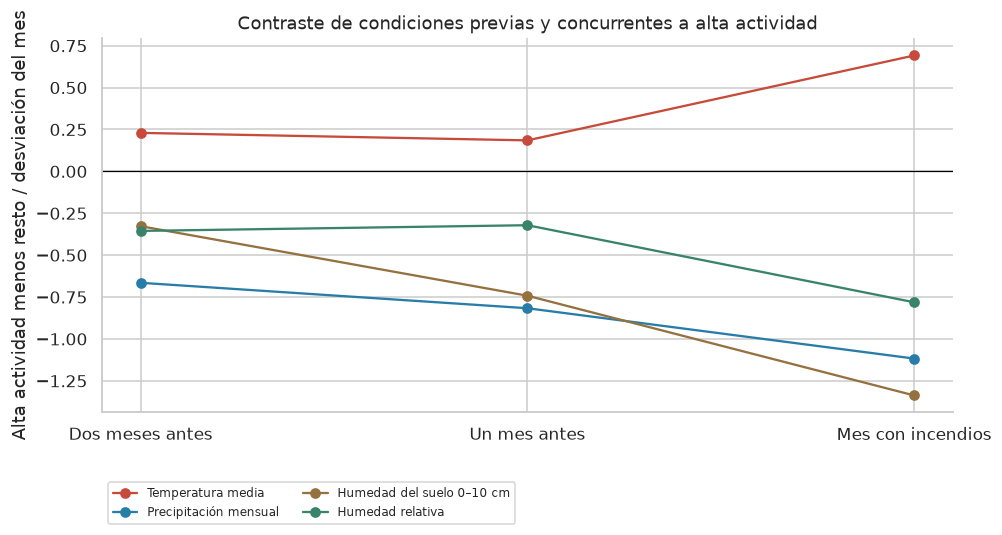

**Meses con más incendios registrados y su contexto ambiental real:**

,fire_count,temperature_2m_c,precipitation_mm,soil_moisture_0_10cm_kgm2,temperature_2m_c_anomaly,precipitation_mm_anomaly,soil_moisture_0_10cm_kgm2_anomaly
month,,,,,,,
2023-01-01,489,17.080,8.651,15.844,1.079,-16.294,-2.406
2016-03-01,473,14.795,22.756,14.742,0.528,-17.016,-1.663
2023-02-01,459,17.467,5.199,13.234,0.899,-13.830,-2.444
2015-02-01,447,15.984,5.816,14.629,-0.584,-13.213,-1.049
2016-02-01,444,15.213,9.024,16.405,-1.355,-10.005,0.727
2020-03-01,431,15.480,20.805,14.751,1.213,-18.967,-1.654


In [20]:
fire_quartile = joint.fire_count.groupby(joint.index.month).transform(lambda x: x.quantile(.75))
high_activity = joint.fire_count.ge(fire_quartile) & joint.index.month.isin(always_fire_calendar_months)
activity_contrasts = []
for lag in range(3):
    antecedent_features = regional_eda[list(CORE)].shift(lag).reindex(joint.index)
    assert antecedent_features.notna().all().all()
    contrast = monthly_group_contrast(antecedent_features, high_activity, always_fire_calendar_months)
    contrast['lag_months'] = lag
    activity_contrasts.append(contrast.reset_index())
activity_contrasts = pd.concat(activity_contrasts, ignore_index=True)
high_activity_now = activity_contrasts.query('lag_months == 0').set_index('variable')

activity_loo = {variable: [] for variable in CORE}
for omitted in sorted(joint.index.year.unique()):
    reduced = joint.loc[joint.index.year != omitted]
    threshold = reduced.fire_count.groupby(reduced.index.month).transform(lambda x: x.quantile(.75))
    reduced_group = reduced.fire_count.ge(threshold)
    comparison = monthly_group_contrast(reduced[list(CORE)], reduced_group, always_fire_calendar_months)
    for variable in CORE:
        activity_loo[variable].append(float(comparison.loc[variable, 'mean_within_month_difference']))
high_activity_now['omit_year_min'] = pd.Series({v: min(x) for v,x in activity_loo.items()})
high_activity_now['omit_year_max'] = pd.Series({v: max(x) for v,x in activity_loo.items()})
display(high_activity_now[['label','unit','mean_within_month_difference','omit_year_min','omit_year_max','n_positive','n_reference']].round(4))
display(activity_contrasts.pivot(index='label', columns='lag_months', values='mean_within_month_difference').round(4))
display(Markdown(
    f"Comparamos **{int(high_activity_now.n_positive.iloc[0])} meses de alta actividad** con "
    f"**{int(high_activity_now.n_reference.iloc[0])} meses restantes con incendios**, siempre dentro del mismo mes calendario.\n\n"
    f"- Durante alta actividad: **{high_activity_now.loc[T,'mean_within_month_difference']:+.2f} °C**, "
    f"**{high_activity_now.loc[P,'mean_within_month_difference']:.1f} mm de lluvia**, "
    f"**{high_activity_now.loc[S,'mean_within_month_difference']:.2f} kg/m² de humedad del suelo** y "
    f"**{high_activity_now.loc['relative_humidity_2m_pct','mean_within_month_difference']:.2f} puntos porcentuales de humedad relativa** frente al resto.\n"
    '- La tabla muestra si esos signos se conservan al retirar un año. Los rangos son sensibilidad, no intervalos de confianza.\n'
    '- Los desfases describen si las diferencias ya aparecían uno o dos meses antes; no prueban que permitan anticipar un incendio individual.'
))
fig, ax = plt.subplots(figsize=(9, 4.7), constrained_layout=True)
for variable in [T,P,S,'relative_humidity_2m_pct']:
    values = activity_contrasts.loc[activity_contrasts.variable.eq(variable)].sort_values('lag_months')
    ax.plot(-values.lag_months, values.standardized_difference, '-o', color=CORE[variable][2], label=CORE[variable][0])
ax.axhline(0, color='black', linewidth=.8)
ax.set(xticks=[-2,-1,0], xticklabels=['Dos meses antes','Un mes antes','Mes con incendios'],
        ylabel='Alta actividad menos resto / desviación del mes',
        title='Contraste de condiciones previas y concurrentes a alta actividad')
ax.legend(loc='upper left', bbox_to_anchor=(0, -.17), fontsize=8, ncol=2)
plt.show()

# Casos con muchos incendios: las anomalías se comparan con el mismo mes de la serie conjunta.
fire_cases = joint.nlargest(6, 'fire_count')[['fire_count', T, P, S]].copy()
for variable in [T,P,S]:
    fire_cases[variable + '_anomaly'] = joint_anomalies.loc[fire_cases.index, variable]
display(Markdown('**Meses con más incendios registrados y su contexto ambiental real:**'))
display(fire_cases.round(3))

## 19. Tabla consultable de incendios y contexto ambiental
Guardamos un solo CSV de **114 filas**, con conteo CONAF, temporada original, presencia, grupo de actividad, las **14 variables ambientales disponibles**, sus anomalías y sus valores del mes anterior. Las figuras resumen seis indicadores principales; la tabla siguiente y el CSV incluyen también punto de rocío, humedad específica, temperatura del suelo, componentes U/V, viento del nivel del modelo y los dos agregados de máximas. No son catorce fuentes independientes: hay variables derivadas o relacionadas. Los agregados de máximas corresponden a extremos de píxeles nativos, no a termómetros en cada incendio.

Las anomalías del mes anterior se calculan contra la referencia de su propio mes de observación en 2014–2023. Las anomalías contemporáneas usan la ventana conjunta 2014-07–2023-12, igual que la sección 14; ambas referencias quedan identificadas en el JSON. Los desfases son antecedentes mensuales, no valores tomados en el lugar del incendio.

Los campos de alta actividad solo se definen en los siete meses calendario donde hubo incendios en todos los años observados. En mayo–septiembre quedan vacíos y el grupo se etiqueta como `outside_activity_comparison`; un valor vacío no se convierte en falso.

In [21]:
additional_labels = {
    'dewpoint_2m_c': 'Punto de rocío a 2 m',
    'specific_humidity_2m_kgkg': 'Humedad específica a 2 m',
    'wind_u_10m_ms': 'Componente U a 10 m',
    'wind_v_10m_ms': 'Componente V a 10 m',
    'wind_speed_lowest_model_ms': 'Viento del nivel inferior del modelo',
    'soil_temperature_0_10cm_c': 'Temperatura del suelo 0–10 cm',
    'temperature_monthly_max_c': 'Mayor extremo térmico de los píxeles',
    'temperature_monthly_peak_area_mean_c': 'Media espacial de extremos térmicos de píxel',
}
all_catalog = {v: (CORE[v][0] if v in CORE else additional_labels[v], UNITS[v]) for v in UNITS}
all_event_weather = regional_eda[list(all_catalog)].reindex(joint.index)
all_event_anomalies = all_event_weather - all_event_weather.groupby(all_event_weather.index.month).transform('mean')
all_weather_anomalies = regional_eda[list(all_catalog)] - regional_eda[list(all_catalog)].groupby(regional_eda.index.month).transform('mean')
all_presence_contrast = monthly_group_contrast(all_event_weather, joint.has_recorded_fire, mixed_calendar_months, all_catalog)
all_activity_contrast = monthly_group_contrast(all_event_weather, high_activity, always_fire_calendar_months, all_catalog)
all_variable_comparison = all_presence_contrast[['label','unit']].copy()
all_variable_comparison['presence_minus_zero'] = all_presence_contrast.mean_within_month_difference
all_variable_comparison['high_activity_minus_rest'] = all_activity_contrast.mean_within_month_difference
display(Markdown('**Contraste de las 14 variables en sus propias unidades:** las columnas comparan poblaciones de meses distintas.'))
display(all_variable_comparison.round(6))
event_context = joint[['fire_count', 'has_recorded_fire']].join(all_event_weather)
event_context['conaf_season'] = fire_raw.set_index('month').temporada.reindex(event_context.index)
eligible_activity = event_context.index.month.isin(always_fire_calendar_months)
event_context['high_activity'] = pd.Series(pd.NA, index=event_context.index, dtype='boolean')
event_context.loc[eligible_activity, 'high_activity'] = high_activity.loc[eligible_activity]
event_context['activity_threshold_count'] = fire_quartile.where(eligible_activity)
event_context['activity_group'] = 'outside_activity_comparison'
event_context.loc[eligible_activity & high_activity, 'activity_group'] = 'high_activity'
event_context.loc[eligible_activity & ~high_activity, 'activity_group'] = 'remaining_with_fire'
for variable in all_catalog:
    event_context[variable + '_anomaly'] = all_event_anomalies[variable]
    event_context[variable + '_previous_month'] = regional_eda[variable].shift(1).reindex(event_context.index)
    event_context[variable + '_previous_month_anomaly'] = all_weather_anomalies[variable].shift(1).reindex(event_context.index)
assert len(event_context) == 114 and not event_context.index.duplicated().any()
assert event_context.drop(columns=['high_activity','activity_threshold_count']).notna().all().all()
assert event_context.loc[eligible_activity].high_activity.notna().all()
assert event_context.loc[~eligible_activity].high_activity.isna().all()
context_path = OUTPUT / 'incendios_contexto_mensual.csv'
event_context.to_csv(context_path, index=True, index_label='month', encoding='utf-8-sig', date_format='%Y-%m')
roundtrip = pd.read_csv(context_path)
assert len(roundtrip) == 114 and roundtrip.month.nunique() == 114
assert roundtrip.fire_count.sum() == joint.fire_count.sum()

exploration_report['fire_event_contrasts'] = {
    'observation_unit': 'One calendar month, entire Araucania region; not individual fire day/location.',
    'with_recorded_fire': int(joint.has_recorded_fire.sum()),
    'without_recorded_fire': int((~joint.has_recorded_fire).sum()),
    'presence_by_calendar_month': presence_calendar.reset_index().to_dict('records'),
    'presence_comparable_calendar_months': mixed_calendar_months,
    'presence_supported_calendar_months': supported_calendar_months,
    'presence_contrast': presence_contrast.reset_index().to_dict('records'),
    'presence_supported_contrast': supported_presence_contrast.reset_index().to_dict('records'),
    'all_14_variable_presence_contrast': all_presence_contrast.reset_index().to_dict('records'),
    'all_14_variable_activity_contrast': all_activity_contrast.reset_index().to_dict('records'),
    'activity_calendar_months': always_fire_calendar_months,
    'activity_definition': 'Count >= 75th percentile within calendar month; only months with fire recorded in every observed year.',
    'activity_now_contrast': high_activity_now.reset_index().to_dict('records'),
    'activity_antecedent_contrasts': activity_contrasts.to_dict('records'),
    'contrast_method': 'Difference of means within calendar month, then equal-weight average across eligible calendar months. Standardized difference divides each month difference by its own sample SD before averaging.',
    'activity_omit_year_method': 'Recalculate count thresholds and groups after excluding each calendar year. Descriptive sensitivity, not a confidence interval.',
    'top_fire_month_cases': fire_cases.reset_index().assign(month=lambda x:x.month.dt.strftime('%Y-%m')).to_dict('records'),
    'limitations': ['Presence comparison is supported only in May-September, and without singleton groups only June-August.',
                    'Fire occurrence and high monthly activity answer different questions and compare different month populations.',
                    'Monthly regional variables cannot locate or describe ignition-day weather.',
                    'No fire causal attribution; shared grids, temporal dependence, potential reporting differences and omitted human/land-use factors.'],
}
exploration_report['event_context_output'] = {
    'file': context_path.name, 'rows': len(event_context),
    'sha256': hashlib.sha256(context_path.read_bytes()).hexdigest(),
    'concurrent_anomaly_reference': 'Calendar-month means over jointly observed months 2014-07/2023-12.',
    'previous_month_anomaly_reference': 'Calendar-month means over full weather period 2014-01/2023-12, shifted by one month.',
    'units': {v: description[1] for v, description in all_catalog.items()},
}
assert source_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
assert conaf_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in conaf_paths}
exploration_path.write_text(json.dumps(exploration_report, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
display(Markdown(
    '**La pista principal es distinguir ocurrencia de actividad:** la sola presencia aparece casi todo el año; '
    'los meses con más incendios se distinguen mejor por menor lluvia, menor humedad superficial del suelo y mayor temperatura respecto de otros años del mismo mes. '
    'El contraste directo con cero registros respalda sobre todo la diferencia de lluvia y no un requisito de calor mensual. '
    'Para saber qué ocurrió al inicio de cada incendio haría falta un registro con fecha y ubicación del evento, acompañado de meteorología a esa escala.'
))
print('CSV de contexto:', context_path.relative_to(ROOT), len(event_context), 'filas')
print('Reporte ampliado:', exploration_path.relative_to(ROOT))
print('Todos los CSV fuente permanecen intactos.')

**Contraste de las 14 variables en sus propias unidades:** las columnas comparan poblaciones de meses distintas.

,label,unit,presence_minus_zero,high_activity_minus_rest
variable,,,,
temperature_2m_c,Temperatura media,°C,-0.204703,0.783993
dewpoint_2m_c,Punto de rocío a 2 m,°C,-0.880488,-0.436963
specific_humidity_2m_kgkg,Humedad específica a 2 m,kg/kg,-0.000314,-0.000193
wind_u_10m_ms,Componente U a 10 m,m/s,-0.249511,0.030724
wind_v_10m_ms,Componente V a 10 m,m/s,0.418027,0.371480
wind_speed_lowest_model_ms,Viento del nivel inferior del modelo,m/s,-0.049390,-0.056497
soil_moisture_0_10cm_kgm2,Humedad del suelo 0–10 cm,kg/m²,-0.968683,-2.621320
soil_temperature_0_10cm_c,Temperatura del suelo 0–10 cm,°C,-0.361894,0.511306
aod_550,Aerosoles AOD 550 nm,adimensional,0.001170,0.008869


**La pista principal es distinguir ocurrencia de actividad:** la sola presencia aparece casi todo el año; los meses con más incendios se distinguen mejor por menor lluvia, menor humedad superficial del suelo y mayor temperatura respecto de otros años del mismo mes. El contraste directo con cero registros respalda sobre todo la diferencia de lluvia y no un requisito de calor mensual. Para saber qué ocurrió al inicio de cada incendio haría falta un registro con fecha y ubicación del evento, acompañado de meteorología a esa escala.

CSV de contexto: datos_mensuales_2014_2023\limpios\incendios_contexto_mensual.csv 114 filas
Reporte ampliado: datos_mensuales_2014_2023\limpios\hallazgos_exploratorios.json
Todos los CSV fuente permanecen intactos.


## 20. Auditoría de meses y grupos antes de inferir
Las cifras anteriores pertenecen a preguntas y subconjuntos distintos. Los seis meses faltantes en el cruce son **enero–junio de 2014, sin registros en el CSV CONAF**, aunque NASA sí tiene datos. CONAF también contiene enero–junio de 2024, fuera del período ambiental solicitado. No se sustituyen por cero.

Los 66 meses del contraste de alta actividad pertenecen exclusivamente a **enero–abril y octubre–diciembre**: esos meses tuvieron incendios en todos los años observados. Los otros **34 meses con incendios** corresponden a mayo–septiembre y quedaron fuera por esa definición, no por falta de datos. Los 14 meses con cero registros completan el cruce.

La regresión siguiente utiliza **los 114 meses**, incluidos los 34 excluidos de aquel contraste y los 14 con cero. La definición de alta actividad no interviene en su ajuste.

In [22]:
cohort_audit = pd.DataFrame([
    {'group': 'Meses ambientales disponibles', 'months': len(regional_eda), 'explanation': '2014-01 a 2023-12'},
    {'group': 'NASA sin coincidencia CONAF', 'months': len(weather_without_fire), 'explanation': ', '.join(weather_without_fire.strftime('%Y-%m'))},
    {'group': 'CONAF fuera del período NASA', 'months': len(fire_outside_weather), 'explanation': ', '.join(fire_outside_weather.strftime('%Y-%m'))},
    {'group': 'Coincidencia: muestra de regresión', 'months': len(joint), 'explanation': '2014-07 a 2023-12; incluye ceros'},
    {'group': 'Con incendios registrados', 'months': int(joint.has_recorded_fire.sum()), 'explanation': '100 = 66 + 34'},
    {'group': 'Cero incendios registrados', 'months': int((~joint.has_recorded_fire).sum()), 'explanation': '14; todos entre mayo y septiembre'},
    {'group': 'Dentro del contraste de actividad', 'months': int(eligible_activity.sum()), 'explanation': '66 = 21 altos + 45 restantes; enero-abril y octubre-diciembre'},
    {'group': 'Con incendios, fuera de ese contraste', 'months': int((joint.has_recorded_fire & ~eligible_activity).sum()), 'explanation': '34; mayo-septiembre'},
])
assert len(regional_eda) == len(joint) + len(weather_without_fire) == 120
assert len(joint) == 100 + 14 == 66 + 34 + 14
assert int(high_activity.sum()) == 21
assert int((eligible_activity & ~high_activity).sum()) == 45
assert joint.index.equals(pd.date_range('2014-07-01','2023-12-01',freq='MS',name='month'))
assert not joint.fire_count.isna().any() and joint.fire_count.mod(1).eq(0).all()
display(cohort_audit)

,group,months,explanation
0,Meses ambientales disponibles,120,2014-01 a 2023-12
1,NASA sin coincidencia CONAF,6,"2014-01, 2014-02, 2014-03, 2014-04, 2014-05, 2..."
2,CONAF fuera del período NASA,6,"2024-01, 2024-02, 2024-03, 2024-04, 2024-05, 2..."
3,Coincidencia: muestra de regresión,114,2014-07 a 2023-12; incluye ceros
4,Con incendios registrados,100,100 = 66 + 34
5,Cero incendios registrados,14,14; todos entre mayo y septiembre
6,Dentro del contraste de actividad,66,66 = 21 altos + 45 restantes; enero-abril y oc...
7,"Con incendios, fuera de ese contraste",34,34; mayo-septiembre


## 21. Regresión binomial negativa: especificación y supuestos
**Pregunta:** ¿qué asociación conserva cada variable con el conteo mensual cuando las cuatro se consideran juntas, controlando el calendario?

Definimos cuatro covariables antes de la inferencia: temperatura, déficit de lluvia, déficit de humedad relativa y déficit de humedad superficial del suelo. Cada una se expresa como desviación respecto de su mismo mes calendario, dividida por la desviación estándar conjunta de esas anomalías. Los déficits cambian el signo: un valor positivo significa menos agua o humedad. No se aplica un umbral de incendios ni se buscan cortes que maximicen significancia.

$$Y_t\sim NB2(\mu_t,\alpha),\qquad \operatorname{Var}(Y_t)=\mu_t+\alpha\mu_t^2$$
$$\log\mu_t=\log(días_t)+\gamma_{mes(t)}+\delta\,tiempo_t+\beta_T z_{T,t}+\beta_P z_{déficit\,P,t}+\beta_H z_{déficit\,HR,t}+\beta_S z_{déficit\,suelo,t}.$$

Se estiman **11 indicadores de mes más intercepto**, una tendencia temporal lineal centrada y cuatro coeficientes ambientales, además de `alpha`. El offset del número de días trata cada mes como tiempo de exposición. `exp(beta)` es una razón de tasas asociada con una desviación estándar de anomalía, manteniendo las demás variables y controles constantes. No es probabilidad de un incendio ni un efecto causal. Las anomalías facilitan la interpretación; son los indicadores de mes quienes controlan explícitamente la estacionalidad.

Se estima `alpha` por máxima verosimilitud con [NB2 de statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.NegativeBinomial.html); no se fija arbitrariamente en 1. Para la inferencia se usa [covarianza HAC Newey–West](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html), con kernel Bartlett, cuatro rezagos y corrección de tamaño. Se comprueban ocho y doce rezagos como sensibilidad. Los intervalos son **asintóticos**: 114 meses no garantizan exactitud en muestra pequeña y HAC no corrige una media mal especificada.

Las cuatro pruebas individuales se ajustan por **Holm**; los IC95 % mostrados son marginales, no simultáneos. Una prueba Wald conjunta contrasta que los cuatro coeficientes ambientales sean cero. La combinación es multivariable y aditiva en la escala logarítmica; no se estiman interacciones ni sinergias. No se crean pronósticos, modelos de riesgo ni selección automática de variables.

In [23]:
import statsmodels, scipy
import statsmodels.api as sm
from scipy.stats import norm, chi2
from statsmodels.discrete.discrete_model import NegativeBinomial
from statsmodels.stats.sandwich_covariance import cov_hac
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests

NB_SPEC = {
    'heat': (T, 'Temperatura más alta', 1),
    'rain_deficit': (P, 'Déficit de lluvia', -1),
    'rh_deficit': ('relative_humidity_2m_pct', 'Déficit de humedad relativa', -1),
    'soil_deficit': (S, 'Déficit de humedad del suelo', -1),
}
NB_TERMS = list(NB_SPEC)
nb_data = joint[['fire_count'] + [spec[0] for spec in NB_SPEC.values()]].copy()
nb_scales, nb_weather = [], pd.DataFrame(index=nb_data.index)
for term,(variable,label,direction) in NB_SPEC.items():
    anomaly = nb_data[variable] - nb_data[variable].groupby(nb_data.index.month).transform('mean')
    scale = float(anomaly.std(ddof=1))
    assert np.isfinite(scale) and scale > 0
    nb_weather[term] = direction * anomaly / scale
    nb_scales.append({'term':term,'variable':variable,'label':label,'one_sd_original_units':scale,
                      'unit':'puntos porcentuales' if variable=='relative_humidity_2m_pct' else UNITS[variable], 'direction':direction})
nb_scales = pd.DataFrame(nb_scales).set_index('term')
month_controls = sm.add_constant(pd.get_dummies(pd.Series(nb_data.index.month,index=nb_data.index),
                                                prefix='month',drop_first=True,dtype=float))
base_controls = month_controls.copy()
base_controls['time_years'] = (np.arange(len(nb_data))-(len(nb_data)-1)/2)/12
nb_design = base_controls.join(nb_weather)
nb_y = nb_data.fire_count.astype(int)
nb_offset = np.log(nb_data.index.days_in_month.to_numpy())
assert len(nb_y) == 114 and nb_y.eq(0).sum() == 14
assert np.linalg.matrix_rank(nb_design) == nb_design.shape[1]

def fit_nb(design):
    result = NegativeBinomial(nb_y,design,offset=nb_offset,loglike_method='nb2').fit(
        method='bfgs',maxiter=1500,gtol=1e-6,disp=0)
    assert bool(result.mle_retvals['converged']), 'El ajuste NB no convergió; no interpretar coeficientes.'
    assert result.params['alpha'] > 0 and np.isfinite(result.params).all()
    assert np.max(np.abs(result.model.score(result.params.to_numpy())))/len(nb_y) < 1e-4
    return result

nb_fit = fit_nb(nb_design)
nb_base_fit = fit_nb(base_controls)
nb_covariances = {lag:cov_hac(nb_fit,nlags=lag,use_correction=True) for lag in [4,8,12]}
for covariance in nb_covariances.values():
    assert covariance.shape == (len(nb_fit.params),len(nb_fit.params))
    assert np.isfinite(covariance).all() and np.diag(covariance).min() > 0
    assert np.linalg.eigvalsh(covariance).min() > -1e-8

poisson_fit = sm.GLM(nb_y,nb_design,offset=nb_offset,family=sm.families.Poisson()).fit()
nb_fitted = pd.Series(nb_fit.predict(nb_design,offset=nb_offset),index=nb_y.index)
nb_pearson_residual = (nb_y-nb_fitted)/np.sqrt(nb_fitted+nb_fit.params['alpha']*nb_fitted**2)
nb_vif = pd.DataFrame([{'term':term,'label':NB_SPEC[term][1],
                       'VIF_after_month_and_trend_controls':float(variance_inflation_factor(nb_design.to_numpy(),nb_design.columns.get_loc(term)))}
                      for term in NB_TERMS])
nb_diagnostics = {
    'n_months':len(nb_y),'zero_count_months':int(nb_y.eq(0).sum()),
    'mean_parameters':int(nb_design.shape[1]),'estimated_parameters_including_alpha':len(nb_fit.params),
    'converged':bool(nb_fit.mle_retvals['converged']),
    'alpha_estimated':float(nb_fit.params['alpha']),
    'conditional_poisson_Pearson_chi2_per_df':float(poisson_fit.pearson_chi2/poisson_fit.df_resid),
    'NB_Pearson_sum_squares_per_mean_residual_df':float((nb_pearson_residual**2).sum()/(len(nb_y)-nb_design.shape[1])),
    'AIC_calendar_trend_only':float(nb_base_fit.aic),'AIC_calendar_trend_four_weather_terms':float(nb_fit.aic),
    'residual_autocorrelation':{str(lag):float(nb_pearson_residual.autocorr(lag)) for lag in range(1,13)},
    'VIF':nb_vif.to_dict('records'),
}
display(nb_scales.round(4))
display(nb_vif.round(3))
display(Markdown(
    f"**Convergencia confirmada.** Poisson presenta una razón Pearson/GL **{nb_diagnostics['conditional_poisson_Pearson_chi2_per_df']:.2f}** "
    f"tras controlar las mismas variables; NB estima **alpha = {nb_fit.params['alpha']:.3f}**. "
    'La razón es un diagnóstico de sobredispersión, no una prueba de que NB sea la única distribución correcta. '
    f"La autocorrelación residual es {nb_pearson_residual.autocorr(1):.2f} a un mes y {nb_pearson_residual.autocorr(12):.2f} a doce; "
    'se mantiene inferencia HAC y se revisan distintas ventanas. '
    'Los VIF se calculan incluyendo los controles de mes y tiempo: las variables relacionadas pueden alterar sus asociaciones condicionales.'
))

,variable,label,one_sd_original_units,unit,direction
term,,,,,
heat,temperature_2m_c,Temperatura más alta,0.8767,°C,1
rain_deficit,precipitation_mm,Déficit de lluvia,49.5958,mm/mes,-1
rh_deficit,relative_humidity_2m_pct,Déficit de humedad relativa,4.5051,puntos porcentuales,-1
soil_deficit,soil_moisture_0_10cm_kgm2,Déficit de humedad del suelo,1.7548,kg/m²,-1


,term,label,VIF_after_month_and_trend_controls
0,heat,Temperatura más alta,2.038
1,rain_deficit,Déficit de lluvia,1.418
2,rh_deficit,Déficit de humedad relativa,3.629
3,soil_deficit,Déficit de humedad del suelo,1.942


**Convergencia confirmada.** Poisson presenta una razón Pearson/GL **7.85** tras controlar las mismas variables; NB estima **alpha = 0.094**. La razón es un diagnóstico de sobredispersión, no una prueba de que NB sea la única distribución correcta. La autocorrelación residual es 0.22 a un mes y 0.20 a doce; se mantiene inferencia HAC y se revisan distintas ventanas. Los VIF se calculan incluyendo los controles de mes y tiempo: las variables relacionadas pueden alterar sus asociaciones condicionales.

## 22. Asociaciones ajustadas, intervalos y prueba conjunta
La tabla presenta asociaciones **condicionales a las otras tres variables**, mes y tendencia. Un IC que incluye 1 no distingue claramente aumento de ausencia de asociación con este método. No se deduce ausencia de efecto físico ni se atribuye un incendio al clima. Los p ajustados por Holm se refieren a las cuatro pruebas ambientales predefinidas.

,label,beta,HAC_standard_error,rate_ratio,CI95_low,CI95_high,p_asymptotic,p_Holm_four_terms,one_sd_original_units,unit
term,,,,,,,,,,
heat,Temperatura más alta,-0.052,0.038,0.949,0.881,1.023,0.171,0.208,0.877,°C
rain_deficit,Déficit de lluvia,0.546,0.075,1.727,1.489,2.002,4.32e-13,1.73e-12,49.596,mm/mes
rh_deficit,Déficit de humedad relativa,-0.113,0.070,0.893,0.779,1.023,0.104,0.208,4.505,puntos porcentuales
soil_deficit,Déficit de humedad del suelo,0.179,0.055,1.196,1.075,1.331,0.00103,0.0031,1.755,kg/m²


**Prueba conjunta de las cuatro variables:** Wald HAC, χ²(4) = 150.63, p = 1.49e-31. Rechazar el bloque nulo no demuestra que cada variable contribuya ni que existan sinergias. La hipótesis y el modelo siguen siendo exploratorios porque surgieron tras examinar estos mismos datos.

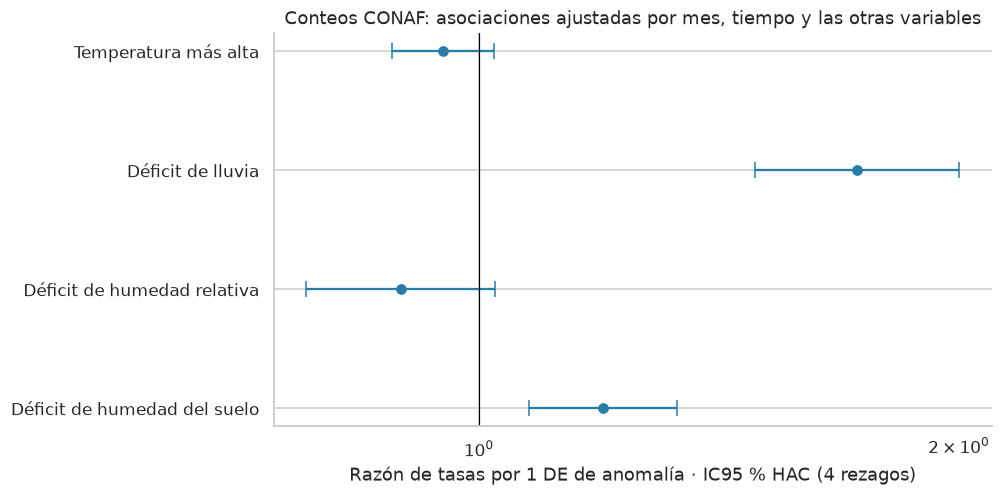

In [24]:
def coefficient_table(result,covariance,terms=NB_TERMS):
    records=[]
    for term in terms:
        i=result.params.index.get_loc(term)
        beta=float(result.params[term]); se=float(np.sqrt(covariance[i,i]))
        z=beta/se; p=float(2*norm.sf(abs(z)))
        records.append({'term':term,'label':NB_SPEC[term][1], 'beta':beta,'HAC_standard_error':se,
                        'rate_ratio':float(np.exp(beta)),
                        'CI95_low':float(np.exp(beta-norm.ppf(.975)*se)),
                        'CI95_high':float(np.exp(beta+norm.ppf(.975)*se)),
                        'p_asymptotic':p})
    table=pd.DataFrame(records).set_index('term')
    table['p_Holm_four_terms']=multipletests(table.p_asymptotic,method='holm')[1]
    return table

nb_coefficients = coefficient_table(nb_fit,nb_covariances[4]).join(nb_scales[['one_sd_original_units','unit']])
R=np.zeros((len(NB_TERMS),len(nb_fit.params)))
for row,term in enumerate(NB_TERMS): R[row,nb_fit.params.index.get_loc(term)]=1
joint_beta=R@nb_fit.params.to_numpy()
joint_cov=R@nb_covariances[4]@R.T
joint_stat=float(joint_beta@np.linalg.solve(joint_cov,joint_beta))
nb_joint_wald={'statistic':joint_stat,'df':len(NB_TERMS),'p_asymptotic':float(chi2.sf(joint_stat,len(NB_TERMS)))}
nb_display=nb_coefficients.round(3).copy()
for column in ['p_asymptotic','p_Holm_four_terms']:
    nb_display[column]=nb_coefficients[column].map(lambda value:f'{value:.3g}')
display(nb_display)
display(Markdown(
    f"**Prueba conjunta de las cuatro variables:** Wald HAC, χ²({len(NB_TERMS)}) = {joint_stat:.2f}, "
    f"p = {nb_joint_wald['p_asymptotic']:.3g}. "
    'Rechazar el bloque nulo no demuestra que cada variable contribuya ni que existan sinergias. '
    'La hipótesis y el modelo siguen siendo exploratorios porque surgieron tras examinar estos mismos datos.'
))
fig,ax=plt.subplots(figsize=(9,4.4),constrained_layout=True)
y=np.arange(len(nb_coefficients))
ax.errorbar(nb_coefficients.rate_ratio,y,
    xerr=np.vstack([nb_coefficients.rate_ratio-nb_coefficients.CI95_low,
                    nb_coefficients.CI95_high-nb_coefficients.rate_ratio]),
    fmt='o',capsize=5,color='#277DA8')
ax.axvline(1,color='black',linewidth=.8)
ax.set(xscale='log',yticks=y,yticklabels=nb_coefficients.label,
        xlabel='Razón de tasas por 1 DE de anomalía · IC95 % HAC (4 rezagos)',
        title='Conteos CONAF: asociaciones ajustadas por mes, tiempo y las otras variables')
ax.invert_yaxis()
plt.show()

## 23. Sensibilidad de la inferencia y de la forma del modelo
Sin escoger la variante por su p, se comparan HAC de 4, 8 y 12 meses; un modelo sin tendencia; un modelo con indicadores de año en lugar de tendencia lineal; y una transformación `log(1 + lluvia)` para revisar la forma de la asociación de precipitación. En esta última cambia la unidad estandarizada y su razón de tasas no es directamente intercambiable con la del modelo principal.

Todas las variantes usan los mismos 114 meses, indicadores de mes, offset de días y cuatro covariables. Las pruebas alternativas son controles exploratorios, no oportunidades adicionales para declarar significancia. Ninguno controla cambios no medidos en ignición humana, uso de suelo, esfuerzo de registro o prácticas de manejo.

,specification,HAC_lags,label,rate_ratio,CI95_low,CI95_high,p_Holm_four_terms
0,main_month_linear_time,4,Temperatura más alta,0.949,0.881,1.023,0.208
1,main_month_linear_time,4,Déficit de lluvia,1.727,1.489,2.002,1.73e-12
2,main_month_linear_time,4,Déficit de humedad relativa,0.893,0.779,1.023,0.208
3,main_month_linear_time,4,Déficit de humedad del suelo,1.196,1.075,1.331,0.0031
4,main_month_linear_time,8,Temperatura más alta,0.949,0.892,1.010,0.152
5,main_month_linear_time,8,Déficit de lluvia,1.727,1.511,1.972,3.49e-15
6,main_month_linear_time,8,Déficit de humedad relativa,0.893,0.788,1.012,0.152
7,main_month_linear_time,8,Déficit de humedad del suelo,1.196,1.078,1.326,0.00209
8,main_month_linear_time,12,Temperatura más alta,0.949,0.897,1.004,0.112
9,main_month_linear_time,12,Déficit de lluvia,1.727,1.518,1.964,3.48e-16


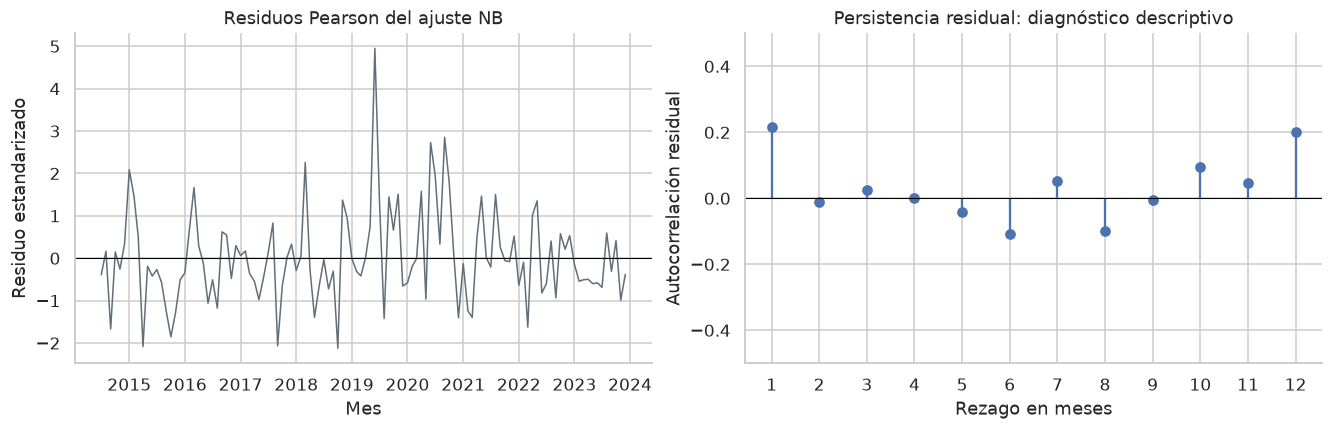

In [25]:
nb_sensitivity=[]
for lag in [4,8,12]:
    table=coefficient_table(nb_fit,nb_covariances[lag]).reset_index()
    table['specification']='main_month_linear_time';table['HAC_lags']=lag
    nb_sensitivity.append(table)
year_controls=pd.get_dummies(pd.Series(nb_y.index.year,index=nb_y.index),prefix='year',drop_first=True,dtype=float)
log_rain=np.log1p(nb_data[P])
log_rain_anomaly=log_rain-log_rain.groupby(log_rain.index.month).transform('mean')
log_weather=nb_weather.copy()
log_weather['rain_deficit']=-log_rain_anomaly/log_rain_anomaly.std()
nb_variants={
    'month_no_time':month_controls.join(nb_weather),
    'month_year_fixed_effects':month_controls.join(year_controls).join(nb_weather),
    'month_linear_time_log1p_rain':base_controls.join(log_weather),
}
nb_variant_diagnostics=[]
for name,design in nb_variants.items():
    assert np.linalg.matrix_rank(design)==design.shape[1]
    variant=fit_nb(design)
    table=coefficient_table(variant,cov_hac(variant,nlags=4,use_correction=True)).reset_index()
    table['specification']=name;table['HAC_lags']=4;nb_sensitivity.append(table)
    nb_variant_diagnostics.append({'specification':name,'converged':bool(variant.mle_retvals['converged']),
                                   'alpha':float(variant.params['alpha']),'n':int(variant.nobs),
                                   'estimated_parameters':len(variant.params)})
nb_sensitivity=pd.concat(nb_sensitivity,ignore_index=True)
nb_sensitivity_display=nb_sensitivity[['specification','HAC_lags','label','rate_ratio','CI95_low','CI95_high','p_Holm_four_terms']].round(3)
nb_sensitivity_display['p_Holm_four_terms']=nb_sensitivity.p_Holm_four_terms.map(lambda value:f'{value:.3g}')
display(nb_sensitivity_display)
fig,axes=plt.subplots(1,2,figsize=(12,3.8),constrained_layout=True)
axes[0].plot(nb_pearson_residual.index,nb_pearson_residual,color='#616F79',linewidth=1)
axes[0].axhline(0,color='black',linewidth=.7)
axes[0].set(title='Residuos Pearson del ajuste NB',ylabel='Residuo estandarizado',xlabel='Mes')
lags=np.arange(1,13)
axes[1].stem(lags,[nb_pearson_residual.autocorr(i) for i in lags],basefmt=' ')
axes[1].axhline(0,color='black',linewidth=.7)
axes[1].set(title='Persistencia residual: diagnóstico descriptivo',xticks=lags,
            xlabel='Rezago en meses',ylabel='Autocorrelación residual',ylim=(-.5,.5))
plt.show()

## 24. Incertidumbre de las diferencias de alta actividad anteriores
Los números `+0,78 °C`, `−34,5 mm`, etc. son diferencias descriptivas de grupos y **no** los coeficientes multivariables NB. Para acompañarlos de incertidumbre se ajusta, por cada variable ambiental, una regresión lineal saturada de mes y de interacción mes × grupo de alta actividad. Un contraste con peso `1/7` sobre los siete coeficientes de grupo reproduce exactamente la media de las siete diferencias originales.

Se conserva el calendario de **114 meses consecutivos** para calcular HAC a cuatro rezagos: no se comprime la serie eliminando mayo–septiembre, lo que alteraría los desfases. Los meses fuera del contraste tienen sus indicadores de mes, sin interacción de actividad. Los IC son asintóticos y condicionales a los grupos observados; no incorporan la incertidumbre de estimar el corte del percentil. Los seis p se ajustan por Holm. Este contraste controla el mes, pero no las otras variables ni la tendencia: la inferencia multivariable principal sigue siendo NB.

In [26]:
activity_design=month_controls.copy()
interaction_names=[]
for calendar_month in always_fire_calendar_months:
    name=f'high_in_month_{calendar_month}'
    activity_design[name]=(high_activity & (joint.index.month==calendar_month)).astype(float)
    interaction_names.append(name)
activity_contrast_vector=np.zeros(activity_design.shape[1])
for name in interaction_names:
    activity_contrast_vector[activity_design.columns.get_loc(name)]=1/len(interaction_names)
activity_inference_records=[]
for variable in CORE:
    group_fit=sm.OLS(joint[variable],activity_design).fit()
    group_cov=cov_hac(group_fit,nlags=4,use_correction=True)
    difference=float(activity_contrast_vector@group_fit.params)
    se=float(np.sqrt(activity_contrast_vector@group_cov@activity_contrast_vector))
    assert np.isclose(difference,high_activity_now.loc[variable,'mean_within_month_difference'])
    activity_inference_records.append({'variable':variable,'label':CORE[variable][0],'unit':CORE[variable][1],
                                       'difference':difference,'HAC_standard_error':se,
                                       'CI95_low':difference-norm.ppf(.975)*se,
                                       'CI95_high':difference+norm.ppf(.975)*se,
                                       'p_asymptotic':float(2*norm.sf(abs(difference/se)))})
activity_inference=pd.DataFrame(activity_inference_records)
activity_inference['p_Holm_six_terms']=multipletests(activity_inference.p_asymptotic,method='holm')[1]
activity_inference_display=activity_inference.round(3).copy()
for column in ['p_asymptotic','p_Holm_six_terms']:
    activity_inference_display[column]=activity_inference[column].map(lambda value:f'{value:.3g}')
display(activity_inference_display)

,variable,label,unit,difference,HAC_standard_error,CI95_low,CI95_high,p_asymptotic,p_Holm_six_terms
0,temperature_2m_c,Temperatura media,°C,0.784,0.197,0.398,1.170,6.75e-05,0.00027
1,precipitation_mm,Precipitación mensual,mm/mes,-34.474,5.591,-45.431,-23.516,7e-10,4.2e-09
2,relative_humidity_2m_pct,Humedad relativa,%,-4.212,1.355,-6.869,-1.556,0.00188,0.00565
3,soil_moisture_0_10cm_kgm2,Humedad del suelo 0–10 cm,kg/m²,-2.621,0.433,-3.471,-1.772,1.46e-09,7.31e-09
4,wind_speed_10m_ms,Viento a 10 m,m/s,-0.013,0.049,-0.110,0.083,0.79,0.79
5,aod_550,Aerosoles AOD 550 nm,adimensional,0.009,0.006,-0.002,0.020,0.113,0.226


## 25. Lectura revisada y exportación reproducible
Las conclusiones se condicionan al modelo y se conservan las estimaciones que no distinguen claramente asociación de cero. Los resultados agregados no explican la fecha ni el lugar de ignición de un incendio individual. La evidencia de estacionalidad fue controlada explícitamente; eso no elimina los demás factores de confusión ni convierte una exploración posterior a observar los datos en confirmación independiente.

In [27]:
supported_terms=nb_coefficients.index[nb_coefficients.p_Holm_four_terms.lt(.05)].tolist()
terms_supported_all_sensitivities=[]
for term in NB_TERMS:
    subset=nb_sensitivity.loc[nb_sensitivity.term.eq(term)]
    if subset.p_Holm_four_terms.lt(.05).all() and (subset.rate_ratio.gt(1).all() or subset.rate_ratio.lt(1).all()):
        terms_supported_all_sensitivities.append(term)
soil_year_sensitivity=nb_sensitivity.loc[(nb_sensitivity.term=='soil_deficit') & (nb_sensitivity.specification=='month_year_fixed_effects')].iloc[0]
display(Markdown(
    '**Modelo principal, con control estacional y temporal:**\n\n' + '\n'.join(
        f"- {row['label']}: razón de tasas **{row['rate_ratio']:.2f}**, IC95 % **{row['CI95_low']:.2f}–{row['CI95_high']:.2f}**, "
        f"p Holm **{row['p_Holm_four_terms']:.3g}** por {row['one_sd_original_units']:.2f} {row['unit']} de anomalía en la dirección definida."
        for _,row in nb_coefficients.iterrows()) +
    '\n\nLas diferencias térmicas de los grupos de alta actividad no se deben interpretar automáticamente como '
    'una contribución térmica independiente. Aquí se distingue el contraste entre grupos del coeficiente ajustado. '
    'La combinación de variables se estudia conjuntamente; no se ha demostrado una sinergia ni causalidad. '
    'Las variantes de sensibilidad y la dependencia residual deben acompañar cualquier conclusión.'
))
display(Markdown(
    '**La sensibilidad modifica la conclusión sobre el suelo.** '
    f"Al controlar cada año por separado, su razón de tasas es **{soil_year_sensitivity.rate_ratio:.2f}**, "
    f"IC95 % **{soil_year_sensitivity.CI95_low:.2f}–{soil_year_sensitivity.CI95_high:.2f}**, "
    f"p Holm **{soil_year_sensitivity.p_Holm_four_terms:.3g}**. "
    'El modelo principal sugiere asociación, pero la contribución independiente del suelo no es estable frente al control temporal. '
    f"La asociación que conserva signo e inferencia ajustada en todas las variantes examinadas es: **{', '.join(NB_SPEC[t][1] for t in terms_supported_all_sensitivities) or 'ninguna'}**. "
    'Esto sigue siendo evidencia exploratoria condicionada a los modelos, no una explicación causal de las igniciones.'
))
model_output_path=OUTPUT/'modelo_conaf_binomial_negativa.csv'
nb_coefficients.to_csv(model_output_path,index=True,index_label='term',encoding='utf-8-sig')
roundtrip_model=pd.read_csv(model_output_path)
assert len(roundtrip_model)==4 and roundtrip_model[['rate_ratio','CI95_low','CI95_high']].gt(0).all().all()
assert np.allclose(roundtrip_model.rate_ratio,np.exp(roundtrip_model.beta))
assert roundtrip_model.CI95_low.le(roundtrip_model.rate_ratio).all()
assert roundtrip_model.CI95_high.ge(roundtrip_model.rate_ratio).all()
exploration_report['inferential_followup']={
    'software':{'statsmodels':statsmodels.__version__,'scipy':scipy.__version__},
    'cohort_audit':cohort_audit.to_dict('records'),
    'primary_model':'NB2 count, log days offset, month fixed effects, centered linear time trend, four standardized within-month weather anomalies.',
    'formula':'log(mu_t) = log(days_t) + calendar_month_FE + linear_time + heat + rain_deficit + rh_deficit + soil_deficit',
    'reference_months':'2014-07/2023-12, 114 consecutive months including 14 zeros; no activity-based exclusion.',
    'coefficient_scale':nb_scales.reset_index().to_dict('records'),
    'diagnostics':nb_diagnostics,
    'primary_HAC':{'kernel':'Bartlett','maxlags':4,'use_correction':True,'asymptotic_normal':True},
    'coefficients':nb_coefficients.reset_index().to_dict('records'),
    'all_fitted_parameters':{str(k):float(v) for k,v in nb_fit.params.items()},
    'coefficient_covariance_HAC4':nb_covariances[4].tolist(),
    'joint_weather_Wald_HAC4':nb_joint_wald,
    'sensitivity':nb_sensitivity.to_dict('records'),
    'sensitivity_diagnostics':nb_variant_diagnostics,
    'terms_supported_all_sensitivity_specifications':terms_supported_all_sensitivities,
    'interpretation_of_soil_sensitivity':'Positive association in primary linear-time model; year fixed effects CI includes 1, so independent contribution is sensitive to temporal control.',
    'activity_group_difference_inference':activity_inference.to_dict('records'),
    'multiplicity':'Holm across four primary NB weather coefficients; Holm separately across six descriptive activity contrasts. CI95 marginal, not simultaneous.',
    'limitations':['Exploratory hypotheses after examining the same data; no independent confirmation.',
                   'Only 114 months; HAC normal inference is asymptotic and bandwidth-sensitive.',
                   'HAC handles covariance, not mean-model misspecification or confounding.',
                   'Group-contrast intervals condition on observed activity groups and their empirical thresholds.',
                   'Weather terms are associated and modeled linearly on log rate; no interaction or causal interpretation.',
                   'No population, land-use or reporting-effort offset is available; days are the only exposure offset.',
                   'The NB model describes counts, not individual ignition probability, burned area or forecasts.'],
    'output':{'file':model_output_path.name,'rows':4,'sha256':hashlib.sha256(model_output_path.read_bytes()).hexdigest()},
    'documentation':['https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.NegativeBinomial.html',
                     'https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html'],
}
assert source_hashes=={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
assert conaf_hashes=={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in conaf_paths}
exploration_path.write_text(json.dumps(exploration_report,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
print('Inferencia documentada:',exploration_path.relative_to(ROOT))
print('Cuatro coeficientes exportados:',model_output_path.relative_to(ROOT))
print('114 meses, 14 ceros; fuentes originales intactas.')

**Modelo principal, con control estacional y temporal:**

- Temperatura más alta: razón de tasas **0.95**, IC95 % **0.88–1.02**, p Holm **0.208** por 0.88 °C de anomalía en la dirección definida.
- Déficit de lluvia: razón de tasas **1.73**, IC95 % **1.49–2.00**, p Holm **1.73e-12** por 49.60 mm/mes de anomalía en la dirección definida.
- Déficit de humedad relativa: razón de tasas **0.89**, IC95 % **0.78–1.02**, p Holm **0.208** por 4.51 puntos porcentuales de anomalía en la dirección definida.
- Déficit de humedad del suelo: razón de tasas **1.20**, IC95 % **1.07–1.33**, p Holm **0.0031** por 1.75 kg/m² de anomalía en la dirección definida.

Las diferencias térmicas de los grupos de alta actividad no se deben interpretar automáticamente como una contribución térmica independiente. Aquí se distingue el contraste entre grupos del coeficiente ajustado. La combinación de variables se estudia conjuntamente; no se ha demostrado una sinergia ni causalidad. Las variantes de sensibilidad y la dependencia residual deben acompañar cualquier conclusión.

**La sensibilidad modifica la conclusión sobre el suelo.** Al controlar cada año por separado, su razón de tasas es **1.09**, IC95 % **0.93–1.28**, p Holm **0.828**. El modelo principal sugiere asociación, pero la contribución independiente del suelo no es estable frente al control temporal. La asociación que conserva signo e inferencia ajustada en todas las variantes examinadas es: **Déficit de lluvia**. Esto sigue siendo evidencia exploratoria condicionada a los modelos, no una explicación causal de las igniciones.

Inferencia documentada: datos_mensuales_2014_2023\limpios\hallazgos_exploratorios.json
Cuatro coeficientes exportados: datos_mensuales_2014_2023\limpios\modelo_conaf_binomial_negativa.csv
114 meses, 14 ceros; fuentes originales intactas.


## 26. Tendencias ambientales: alcance y método
**Pregunta:** ¿qué dirección y magnitud tienen los cambios de temperatura, precipitación, humedad relativa y humedad superficial del suelo en La Araucanía y sus comunas durante **2014–2023**?

Estas estimaciones usan **120 meses ambientales**, independientemente del cruce con CONAF. Hay cuatro series regionales y 128 candidatas comunales; se ajustan **131 series** y se conserva una fila sin estimación para el suelo de Saavedra, excluido por cobertura inferior al 80 %. No se imputan datos ni se eliminan extremos. Se exigen los 120 meses utilizables para preservar una serie consecutiva al calcular HAC.

Para cada variable y territorio se estima por mínimos cuadrados:
$$y_t=\alpha+\sum_{m=2}^{12}\gamma_m\,I(mes_t=m)+\beta\,tiempo_{décadas,t}+\varepsilon_t.$$
La pendiente es un cambio por década dentro de la ventana observada, **no una predicción ni la diferencia directa entre los extremos**. El ciclo estacional tiene un nivel propio para cada mes y la tendencia lineal es común a los doce meses. Temperatura se expresa en °C/década, humedad relativa en **puntos porcentuales/década**, suelo en kg/m²/década y precipitación en **mm de precipitación mensual por década**; esta última no es una pendiente del acumulado anual.

Los IC95 % y p son asintóticos, con [covarianza HAC Bartlett](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html) y corrección de tamaño. Se fija **12 rezagos como especificación principal**, revisando 4, 8 y 18 sin seleccionar el resultado más favorable. Se aplica [Holm](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html) a dos familias explícitas: cuatro pruebas regionales principales y 127 pruebas comunales exploratorias, reuniendo las cuatro variables. La dependencia entre comunas no aumenta el número de observaciones temporales.

Los IC95 % son **marginales**, no intervalos simultáneos: pueden excluir cero aunque el p corregido por Holm no alcance 0,05. La clasificación de evidencia utiliza el p corregido. HAC atiende la covarianza temporal, pero no corrige por sí solo no linealidad, cambios del producto o factores causales no medidos. Diez ciclos anuales permiten describir este intervalo; la significancia no demuestra persistencia climática a largo plazo.

In [28]:
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.sandwich_covariance import cov_hac
from statsmodels.stats.multitest import multipletests

TREND_SPEC={
    'temperature_2m_c':{'label':'Temperatura media','unit':'°C','rate_unit':'°C/década','color':'#C74A3A','coverage':'meteorologia_mensual_valid_area_pct'},
    'precipitation_mm':{'label':'Precipitación mensual','unit':'mm/mes','rate_unit':'mm/mes por década','color':'#277DA8','coverage':'precipitacion_mensual_valid_area_pct'},
    'relative_humidity_2m_pct':{'label':'Humedad relativa','unit':'%','rate_unit':'puntos porcentuales/década','color':'#39836B','coverage':None},
    'soil_moisture_0_10cm_kgm2':{'label':'Humedad del suelo 0–10 cm','unit':'kg/m²','rate_unit':'kg/m²/década','color':'#94713F','coverage':'suelo_mensual_valid_area_pct'},
}
TREND_PRIMARY_LAG=12
TREND_LAGS=[4,8,12,18]
TREND_ALPHA=.05
trend_calendar=pd.DatetimeIndex(EXPECTED_MONTHS,name='month')
trend_design=sm.add_constant(pd.get_dummies(pd.Series(trend_calendar.month,index=trend_calendar),
                                           prefix='calendar_month',drop_first=True,dtype=float))
trend_design['time_decades']=(np.arange(len(trend_calendar))-(len(trend_calendar)-1)/2)/120
assert len(trend_calendar)==120 and np.allclose(np.diff(trend_design.time_decades),1/120)
assert np.linalg.matrix_rank(trend_design)==13
trend_time_position=trend_design.columns.get_loc('time_decades')
trend_keys=['geography_level','territory_id','variable']
trend_regional_fits={}
trend_records=[]
trend_bandwidth_records=[]

def fit_environmental_trend(frame,level,identifier,name,variable):
    assert not frame.month.duplicated().any()
    indexed=frame.set_index('month').sort_index()
    assert indexed.index.equals(trend_calendar), 'Calendario inesperado; no comprimir huecos temporales.'
    spec=TREND_SPEC[variable]
    measured=indexed[variable].astype(float)
    usable=measured.copy()
    if variable=='soil_moisture_0_10cm_kgm2':
        usable=usable.where(indexed.soil_coverage_ok)
    coverage=float(indexed[spec['coverage']].min()) if spec['coverage'] else np.nan
    record={'geography_level':level,'territory_id':str(identifier),'territory_name':name,
            'variable':variable,'variable_label':spec['label'],'native_unit':spec['unit'],'rate_unit':spec['rate_unit'],
            'period_start':'2014-01','period_end':'2023-12','n_expected':120,
            'n_measurements':int(measured.notna().sum()),'n_used':int(usable.notna().sum()),
            'usable_temporal_coverage_pct':float(usable.notna().mean()*100),
            'minimum_spatial_coverage_pct':coverage,
            'status':'pending_adjustment' if usable.notna().all() else 'insufficient_coverage',
            'exclusion_reason':'' if usable.notna().all() else 'Soil coverage below 80%; values retained in source, excluded from trend.',
    }
    if not usable.notna().all():
        return record,None,[]
    fitted=sm.OLS(usable,trend_design).fit()
    beta=float(fitted.params.iloc[trend_time_position])
    # Control independiente: en diez años completos y balanceados, la pendiente
    # con indicadores mensuales coincide con la pendiente de las medias anuales.
    yearly_means=usable.groupby(usable.index.year).mean()
    annual_beta=float(np.polyfit(yearly_means.index.to_numpy()-yearly_means.index.to_numpy().mean(),yearly_means.to_numpy(),1)[0]*10)
    assert np.isclose(beta,annual_beta,rtol=1e-9,atol=1e-9)
    record.update({'slope_per_decade':beta,'slope_per_year':beta/10,
                   'fitted_change_over_observed_span':beta*float(trend_design.time_decades.iloc[-1]-trend_design.time_decades.iloc[0]),
                   'residual_df':int(fitted.df_resid),'residual_acf1':float(fitted.resid.autocorr(1)),
                   'residual_acf12':float(fitted.resid.autocorr(12))})
    bandwidth=[]
    for lag in TREND_LAGS:
        covariance=cov_hac(fitted,nlags=lag,use_correction=True)
        assert np.isfinite(covariance).all()
        se=float(np.sqrt(covariance[trend_time_position,trend_time_position]))
        assert se>0
        bandwidth.append({'geography_level':level,'territory_id':str(identifier),'variable':variable,
                          'HAC_lags':lag,'slope_per_decade':beta,'standard_error_per_decade':se,
                          'CI95_low_per_decade':beta-norm.ppf(.975)*se,
                          'CI95_high_per_decade':beta+norm.ppf(.975)*se,
                          'p_raw':float(2*norm.sf(abs(beta/se)))})
    return record,fitted,bandwidth

for variable in TREND_SPEC:
    rec,fitted,bands=fit_environmental_trend(region,'region','09','La Araucanía',variable)
    trend_records.append(rec);trend_bandwidth_records.extend(bands);trend_regional_fits[variable]=fitted
for (identifier,name),frame in communes.groupby(['commune_id','commune_name'],observed=True,sort=True):
    for variable in TREND_SPEC:
        rec,_,bands=fit_environmental_trend(frame,'commune',identifier,name,variable)
        trend_records.append(rec);trend_bandwidth_records.extend(bands)

trend_results=pd.DataFrame(trend_records)
trend_bandwidths=pd.DataFrame(trend_bandwidth_records)
trend_bandwidths['p_holm']=np.nan
trend_bandwidths['family_n_tests']=0
for (level,lag),group in trend_bandwidths.groupby(['geography_level','HAC_lags'],sort=False):
    expected=4 if level=='region' else 127
    assert len(group)==expected
    trend_bandwidths.loc[group.index,'p_holm']=multipletests(group.p_raw,method='holm')[1]
    trend_bandwidths.loc[group.index,'family_n_tests']=expected
primary=trend_bandwidths.loc[trend_bandwidths.HAC_lags.eq(TREND_PRIMARY_LAG)].drop(columns='slope_per_decade')
trend_results=trend_results.merge(primary,on=trend_keys,how='left',validate='one_to_one')
valid_trends=trend_results.n_used.eq(120)
trend_results.loc[valid_trends,'status']=np.where(
    trend_results.loc[valid_trends,'p_holm'].lt(TREND_ALPHA),
    np.where(trend_results.loc[valid_trends,'slope_per_decade'].gt(0),'evidence_increasing','evidence_decreasing'),
    'uncertain_trend')
trend_results['direction']=np.where(trend_results.slope_per_decade.gt(0),'increasing',
                                    np.where(trend_results.slope_per_decade.lt(0),'decreasing','not_estimated'))
for lag in TREND_LAGS:
    sens=trend_bandwidths.loc[trend_bandwidths.HAC_lags.eq(lag),trend_keys+['p_holm']].rename(columns={'p_holm':f'p_holm_HAC{lag}'})
    trend_results=trend_results.merge(sens,on=trend_keys,how='left',validate='one_to_one')
trend_results['evidence_all_bandwidths']=pd.Series(pd.NA,index=trend_results.index,dtype='boolean')
trend_results.loc[valid_trends,'evidence_all_bandwidths']=trend_results.loc[valid_trends,[f'p_holm_HAC{k}' for k in TREND_LAGS]].lt(TREND_ALPHA).all(axis=1)
assert len(trend_results)==132 and int(valid_trends.sum())==131
assert len(trend_bandwidths)==131*len(TREND_LAGS)
assert not trend_results.duplicated(trend_keys).any()
assert trend_results.loc[valid_trends,'p_holm'].ge(trend_results.loc[valid_trends,'p_raw']-1e-12).all()
excluded_trends=trend_results.loc[~valid_trends]
assert len(excluded_trends)==1 and excluded_trends.iloc[0].territory_name=='Saavedra'
assert excluded_trends.iloc[0].variable=='soil_moisture_0_10cm_kgm2'
regional_trends=trend_results.loc[trend_results.geography_level.eq('region')].set_index('variable').reindex(TREND_SPEC)
communal_trends=trend_results.loc[trend_results.geography_level.eq('commune')].copy()
print('131 tendencias ajustadas; una fila explícita sin estimación para suelo de Saavedra.')

131 tendencias ajustadas; una fila explícita sin estimación para suelo de Saavedra.


## 27. Tendencias regionales: magnitud e incertidumbre
Los puntos y líneas finas son los valores mensuales una vez restado el componente estacional estimado, conservando la media y las unidades de la variable. La línea negra es la tendencia ajustada y la banda es un IC95 % marginal de esa media, no un intervalo para cada observación. Las series originales con su ciclo anual permanecen en la sección 4.

La precipitación conserva su significado de **total mensual**: una pendiente de −10 mm/mes por década describe una reducción estimada de diez milímetros en el total de un mes, por década. No significa diez milímetros menos de precipitación anual. La humedad relativa cambia en puntos porcentuales, no en porcentaje relativo.

El ajuste estacional del gráfico es **aditivo** y puede producir niveles ajustados negativos de precipitación. Son valores transformados al retirar el componente mensual, no mediciones de lluvia negativa. Los totales observados sin esta transformación se muestran en la sección 4 y permanecen intactos en los CSV fuente.

,variable_label,rate_unit,slope_per_decade,CI95_low_per_decade,CI95_high_per_decade,p_raw,p_holm,status,evidence_all_bandwidths
variable,,,,,,,,,
temperature_2m_c,Temperatura media,°C/década,0.652,-0.073,1.377,0.0779,0.134,uncertain_trend,False
precipitation_mm,Precipitación mensual,mm/mes por década,-37.091,-72.033,-2.149,0.0375,0.112,uncertain_trend,False
relative_humidity_2m_pct,Humedad relativa,puntos porcentuales/década,-9.343,-12.850,-5.837,1.77e-07,7.06e-07,evidence_decreasing,True
soil_moisture_0_10cm_kgm2,Humedad del suelo 0–10 cm,kg/m²/década,-1.478,-3.061,0.104,0.0671,0.134,uncertain_trend,False


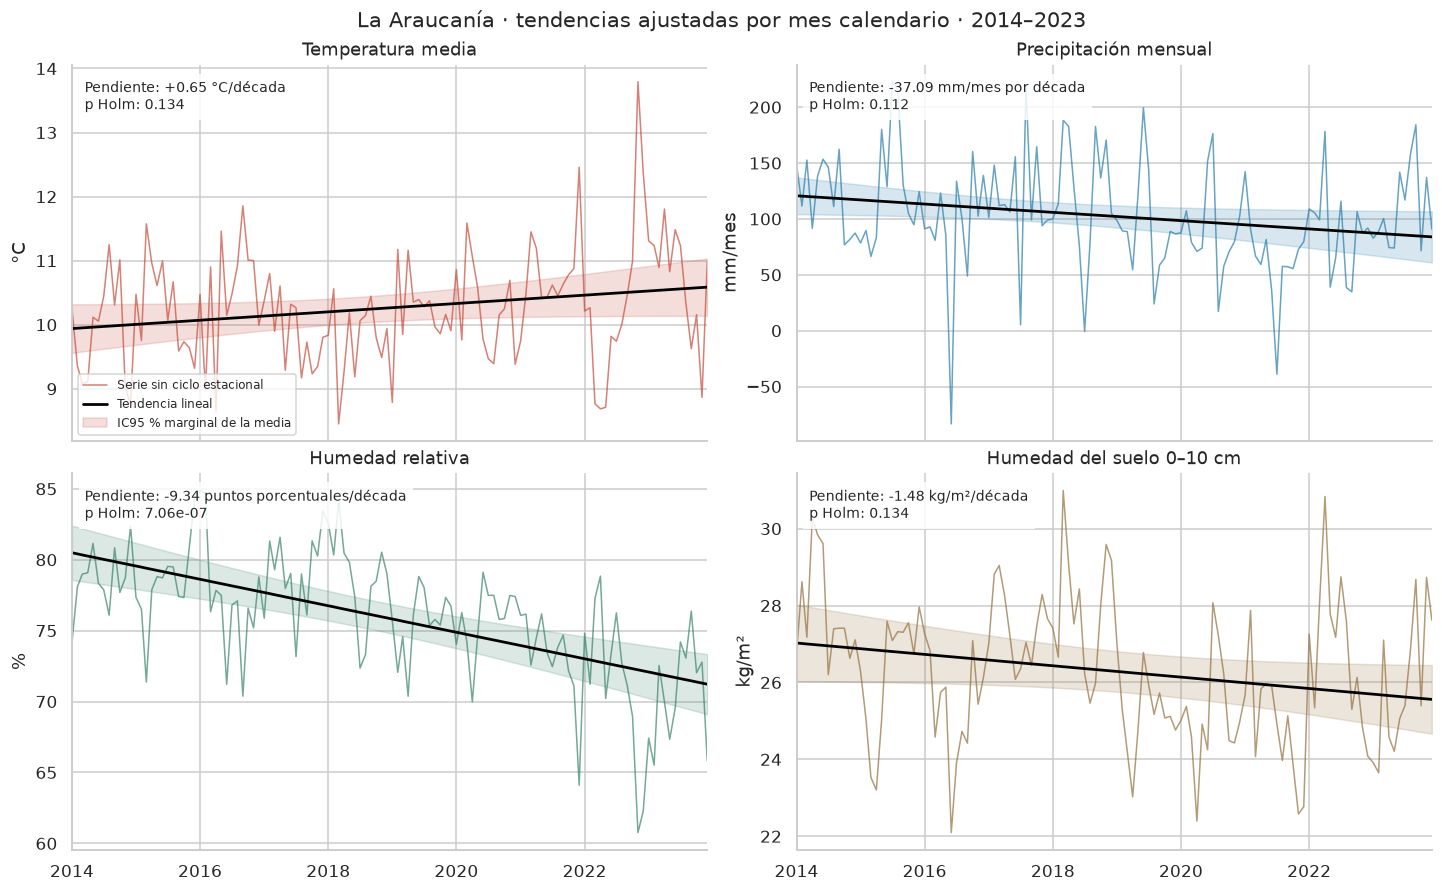

In [29]:
regional_trend_display=regional_trends[['variable_label','rate_unit','slope_per_decade','CI95_low_per_decade',
                                     'CI95_high_per_decade','p_raw','p_holm','status','evidence_all_bandwidths']].round(3)
for column in ['p_raw','p_holm']:
    regional_trend_display[column]=regional_trends[column].map(lambda value:f'{value:.3g}')
display(regional_trend_display)

fig,axes=plt.subplots(2,2,figsize=(13,8),sharex=True,constrained_layout=True)
trend_region_series=region.set_index('month')
for ax,(variable,spec) in zip(axes.flat,TREND_SPEC.items()):
    fitted=trend_regional_fits[variable]
    curve_design=trend_design.copy()
    seasonal_columns=[column for column in trend_design if column.startswith('calendar_month_')]
    curve_design[seasonal_columns]=trend_design[seasonal_columns].mean().to_numpy()
    trend_curve=curve_design.to_numpy()@fitted.params.to_numpy()
    seasonal_component=(trend_design.to_numpy()@fitted.params.to_numpy())-trend_curve
    adjusted_observations=trend_region_series[variable].to_numpy()-seasonal_component
    covariance=cov_hac(fitted,nlags=TREND_PRIMARY_LAG,use_correction=True)
    curve_se=np.sqrt(np.einsum('ij,jk,ik->i',curve_design.to_numpy(),covariance,curve_design.to_numpy()))
    ax.plot(trend_calendar,adjusted_observations,color=spec['color'],linewidth=1,alpha=.7,label='Serie sin ciclo estacional')
    ax.plot(trend_calendar,trend_curve,color='black',linewidth=1.8,label='Tendencia lineal')
    ax.fill_between(trend_calendar,trend_curve-norm.ppf(.975)*curve_se,trend_curve+norm.ppf(.975)*curve_se,
                    color=spec['color'],alpha=.18,label='IC95 % marginal de la media')
    result=regional_trends.loc[variable]
    ax.set(title=spec['label'],ylabel=spec['unit'],
            xlim=(trend_calendar[0],trend_calendar[-1]))
    ax.text(.02,.96,f"Pendiente: {result.slope_per_decade:+.2f} {spec['rate_unit']}\np Holm: {result.p_holm:.3g}",
            transform=ax.transAxes,va='top',fontsize=9,bbox={'facecolor':'white','alpha':.85,'edgecolor':'none'})
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0,0].legend(loc='lower left',fontsize=8)
fig.suptitle('La Araucanía · tendencias ajustadas por mes calendario · 2014–2023',fontsize=14)
plt.show()

## 28. Tendencias comunales: dónde cambia y dónde falta evidencia
Cada celda informa la pendiente en la unidad del encabezado. El color divide esa pendiente por la desviación estándar de las anomalías regionales de la misma variable, para comparar escalas distintas; **los textos conservan unidades físicas**. Un asterisco indica `p Holm < 0,05` dentro de las 127 pruebas comunales. Sin asterisco significa evidencia insuficiente tras la corrección, no ausencia demostrada de cambio. `×` señala suelo excluido por cobertura, no tendencia cero.

Los agregados se refieren a límites administrativos fijos de referencia SMA 2024. Varias comunas comparten píxeles nativos: este gráfico no crea mayor resolución ni permite tratar las comunas como réplicas espaciales independientes. No hay geometrías ni datos de incendios nuevos en esta etapa.

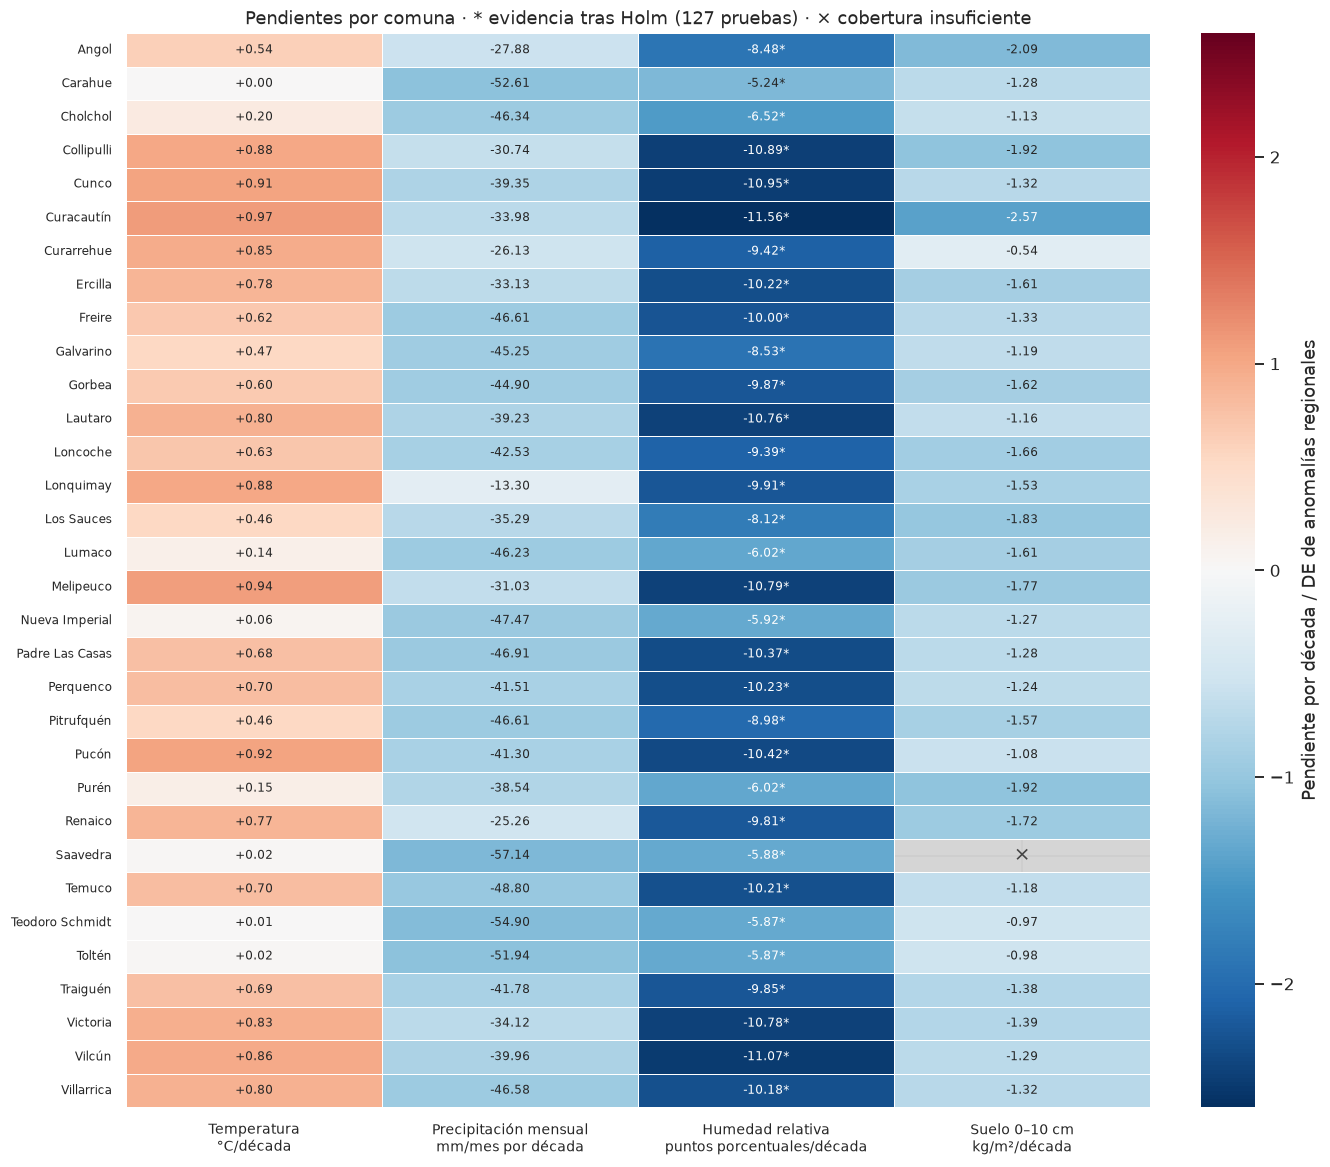

status,evidence_decreasing,insufficient_coverage,uncertain_trend
variable,,,
temperature_2m_c,0,0,32
precipitation_mm,0,0,32
relative_humidity_2m_pct,32,0,0
soil_moisture_0_10cm_kgm2,0,1,31


In [30]:
trend_names=communes[['commune_id','commune_name']].drop_duplicates().sort_values('commune_name')
trend_order=trend_names.commune_id.tolist()
communal_slope=communal_trends.pivot(index='territory_id',columns='variable',values='slope_per_decade').reindex(index=trend_order,columns=TREND_SPEC)
communal_p=communal_trends.pivot(index='territory_id',columns='variable',values='p_holm').reindex_like(communal_slope)
regional_anomaly_sd=pd.Series({variable:float((trend_region_series[variable]-trend_region_series[variable].groupby(trend_calendar.month).transform('mean')).std()) for variable in TREND_SPEC})
normalized_slopes=communal_slope.div(regional_anomaly_sd,axis=1)
annotations=communal_slope.copy().astype('object')
for identifier in annotations.index:
    for variable in annotations.columns:
        value=communal_slope.loc[identifier,variable]
        annotations.loc[identifier,variable]='' if pd.isna(value) else f"{value:+.2f}{'*' if communal_p.loc[identifier,variable]<TREND_ALPHA else ''}"
bound=float(np.nanmax(np.abs(normalized_slopes.to_numpy())))
fig,ax=plt.subplots(figsize=(12,10.5),constrained_layout=True)
ax.set_facecolor('#D5D5D5')
sns.heatmap(normalized_slopes,mask=normalized_slopes.isna(),annot=annotations,fmt='',
            cmap='RdBu_r',center=0,vmin=-bound,vmax=bound,linewidths=.5,linecolor='white',
            yticklabels=trend_names.commune_name.tolist(),annot_kws={'fontsize':8},
            cbar_kws={'label':'Pendiente por década / DE de anomalías regionales'},ax=ax)
ax.set_xticklabels(['Temperatura\n°C/década','Precipitación mensual\nmm/mes por década',
                    'Humedad relativa\npuntos porcentuales/década','Suelo 0–10 cm\nkg/m²/década'],rotation=0,fontsize=9)
for row,column in np.argwhere(communal_slope.isna().to_numpy()):
    ax.text(column+.5,row+.5,'×',ha='center',va='center',color='#444444',fontsize=13)
ax.set(xlabel='',ylabel='',title='Pendientes por comuna · * evidencia tras Holm (127 pruebas) · × cobertura insuficiente')
ax.tick_params(axis='y',labelsize=8)
plt.show()
communal_trend_counts=communal_trends.groupby(['variable','status'],observed=True).size().unstack(fill_value=0).reindex(TREND_SPEC)
display(communal_trend_counts)

## 29. Robustez: autocorrelación y años influyentes
La tabla compara cuatro ventanas HAC con las mismas pendientes: cambia su incertidumbre, no los datos ni el ajuste. Holm se recalcula sobre las mismas familias para cada ventana. No se escoge la ventana por significancia; la principal sigue siendo doce meses.

También se retira cada año por turno y se recalcula **solo la pendiente** con el mes calendario y el eje temporal original. Los huecos de un año no se comprimen. El rango obtenido es sensibilidad al período, no un IC. No se calcula HAC sobre esas series discontinuas. Ningún año se elimina de las estimaciones principales.

,label,HAC_lags,slope_per_decade,CI95_low_per_decade,CI95_high_per_decade,p_holm
0,Temperatura media,4,0.652,-0.232,1.536,0.232
1,Temperatura media,8,0.652,-0.193,1.497,0.234
2,Temperatura media,12,0.652,-0.073,1.377,0.134
3,Temperatura media,18,0.652,0.095,1.209,0.0654
4,Precipitación mensual,4,-37.091,-75.817,1.635,0.181
5,Precipitación mensual,8,-37.091,-75.354,1.172,0.172
6,Precipitación mensual,12,-37.091,-72.033,-2.149,0.112
7,Precipitación mensual,18,-37.091,-70.228,-3.954,0.0654
8,Humedad relativa,4,-9.343,-12.820,-5.866,5.56e-07
9,Humedad relativa,8,-9.343,-13.011,-5.675,2.39e-06


,mínimo al retirar un año,máximo al retirar un año
variable,,
temperature_2m_c,0.507,0.794
precipitation_mm,-57.430,-26.180
relative_humidity_2m_pct,-10.545,-8.425
soil_moisture_0_10cm_kgm2,-2.128,-0.718


**Cantidad de comunas con evidencia de tendencia tras Holm, por ventana HAC:**

HAC_lags,4,8,12,18
variable,,,,
temperature_2m_c,0,0,0,0
precipitation_mm,0,0,0,6
relative_humidity_2m_pct,32,32,32,32
soil_moisture_0_10cm_kgm2,0,0,0,0


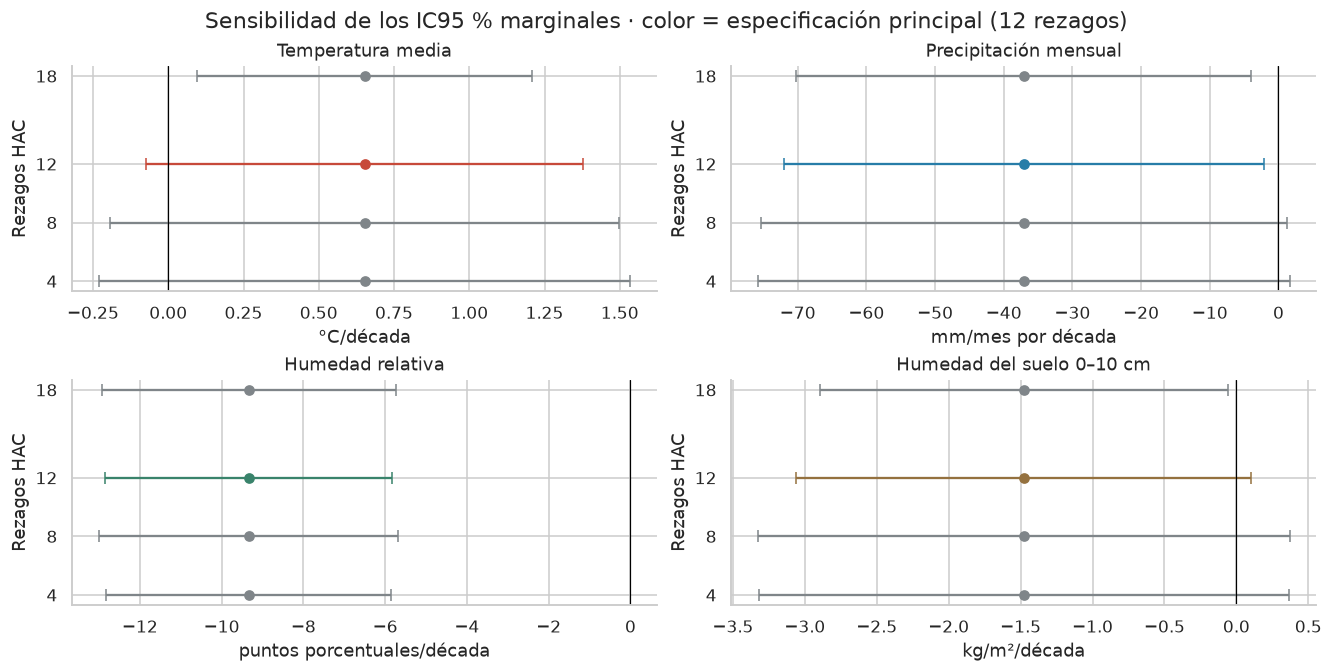

In [31]:
regional_bandwidth_sensitivity=trend_bandwidths.loc[trend_bandwidths.geography_level.eq('region')].copy()
regional_bandwidth_sensitivity['label']=regional_bandwidth_sensitivity.variable.map(lambda value:TREND_SPEC[value]['label'])
regional_sensitivity_display=regional_bandwidth_sensitivity[['label','HAC_lags','slope_per_decade','CI95_low_per_decade','CI95_high_per_decade','p_holm']].round(3)
regional_sensitivity_display['p_holm']=regional_bandwidth_sensitivity.p_holm.map(lambda value:f'{value:.3g}')
display(regional_sensitivity_display)
trend_omit_year_records=[]
for variable in TREND_SPEC:
    for omitted_year in range(2014,2024):
        keep=trend_calendar.year!=omitted_year
        fit=sm.OLS(trend_region_series.loc[keep,variable],trend_design.loc[keep]).fit()
        trend_omit_year_records.append({'variable':variable,'omitted_year':omitted_year,
                                        'n_used':int(keep.sum()),'slope_per_decade':float(fit.params['time_decades'])})
trend_omit_year=pd.DataFrame(trend_omit_year_records)
trend_omit_summary=trend_omit_year.groupby('variable').slope_per_decade.agg(['min','max']).reindex(TREND_SPEC)
display(trend_omit_summary.rename(columns={'min':'mínimo al retirar un año','max':'máximo al retirar un año'}).round(3))
communal_bandwidth_counts=trend_bandwidths.loc[trend_bandwidths.geography_level.eq('commune')].assign(
    evidence=lambda frame:frame.p_holm.lt(TREND_ALPHA)).groupby(['variable','HAC_lags']).evidence.sum().unstack().reindex(TREND_SPEC)
display(Markdown('**Cantidad de comunas con evidencia de tendencia tras Holm, por ventana HAC:**'))
display(communal_bandwidth_counts)
fig,axes=plt.subplots(2,2,figsize=(12,6),constrained_layout=True)
for ax,(variable,spec) in zip(axes.flat,TREND_SPEC.items()):
    values=regional_bandwidth_sensitivity.loc[regional_bandwidth_sensitivity.variable.eq(variable)].sort_values('HAC_lags')
    for _,row in values.iterrows():
        color=spec['color'] if row.HAC_lags==TREND_PRIMARY_LAG else '#7F8589'
        ax.errorbar(row.slope_per_decade,row.HAC_lags,
                    xerr=np.array([[row.slope_per_decade-row.CI95_low_per_decade],[row.CI95_high_per_decade-row.slope_per_decade]]),
                    fmt='o',color=color,capsize=4)
    ax.axvline(0,color='black',linewidth=.8)
    ax.set(title=spec['label'],xlabel=spec['rate_unit'],ylabel='Rezagos HAC',yticks=TREND_LAGS)
fig.suptitle('Sensibilidad de los IC95 % marginales · color = especificación principal (12 rezagos)')
plt.show()

## 30. Qué tendencias respaldan estos datos
Se reportan las cuatro variables, incluyendo pendientes inciertas. Los resultados se refieren al período elegido y a cada producto fuente. Una tendencia significativa no establece su causa ni implica un aumento o disminución de incendios. La regresión asociativa de las secciones anteriores responde a otra pregunta.

In [32]:
trend_findings=[]
for variable,row in regional_trends.iterrows():
    evidence='con evidencia tras Holm' if row.p_holm<TREND_ALPHA else 'sin evidencia suficiente tras Holm'
    trend_findings.append(f"- **{row.variable_label}: {row.slope_per_decade:+.2f} {row.rate_unit}**, "
                          f"IC95 % [{row.CI95_low_per_decade:+.2f}, {row.CI95_high_per_decade:+.2f}], "
                          f"p Holm {row.p_holm:.3g}; {evidence}.")
display(Markdown('\n'.join(trend_findings)))
stable_regional=regional_trends.index[regional_trends.evidence_all_bandwidths.fillna(False)].tolist()
display(Markdown(
    '**Evidencia regional en las cuatro ventanas HAC examinadas:** '+
    (', '.join(TREND_SPEC[value]['label'] for value in stable_regional) if stable_regional else 'ninguna variable')+'. '
    'Las tablas comunales muestran la extensión administrativa de las señales; no son porcentajes de superficie. '
    'No se interpreta un resultado incierto como una pendiente exactamente cero. '
    'Las conclusiones siguen siendo exploratorias: diez años, fuentes modeladas o satelitales agregadas y pruebas asintóticas.'
))

- **Temperatura media: +0.65 °C/década**, IC95 % [-0.07, +1.38], p Holm 0.134; sin evidencia suficiente tras Holm.
- **Precipitación mensual: -37.09 mm/mes por década**, IC95 % [-72.03, -2.15], p Holm 0.112; sin evidencia suficiente tras Holm.
- **Humedad relativa: -9.34 puntos porcentuales/década**, IC95 % [-12.85, -5.84], p Holm 7.06e-07; con evidencia tras Holm.
- **Humedad del suelo 0–10 cm: -1.48 kg/m²/década**, IC95 % [-3.06, +0.10], p Holm 0.134; sin evidencia suficiente tras Holm.

**Evidencia regional en las cuatro ventanas HAC examinadas:** Humedad relativa. Las tablas comunales muestran la extensión administrativa de las señales; no son porcentajes de superficie. No se interpreta un resultado incierto como una pendiente exactamente cero. Las conclusiones siguen siendo exploratorias: diez años, fuentes modeladas o satelitales agregadas y pruebas asintóticas.

## 31. Exportación compacta y trazabilidad de tendencias
Se guarda un CSV con **132 filas candidatas: 131 ajustes y una exclusión explícita**. Cada fila identifica territorio, variable, período, unidades, pendiente, incertidumbre, p corregido, cobertura y sensibilidad a la ventana HAC. El archivo se puede filtrar y unir a geometrías comunales futuras mediante `territory_id`, leído como texto para conservar sus ceros iniciales.

El JSON conserva método, fuentes y hashes, decisiones de multiplicidad, resultados regionales, sensibilidad y límites. No se añaden registros de mediciones, geometrías, pronósticos ni archivos por localidad. Los resultados de tendencias no necesitan la cobertura parcial de CONAF.

In [33]:
trend_csv_path=OUTPUT/'tendencias_ambientales_2014_2023.csv'
trend_json_path=OUTPUT/'reporte_tendencias.json'
trend_results.to_csv(trend_csv_path,index=False,encoding='utf-8-sig')
trend_roundtrip=pd.read_csv(trend_csv_path,dtype={'territory_id':'string'})
assert len(trend_roundtrip)==132 and not trend_roundtrip.duplicated(trend_keys).any()
assert int(trend_roundtrip.n_used.eq(120).sum())==131
assert trend_roundtrip.loc[trend_roundtrip.geography_level.eq('commune'),'territory_id'].str.fullmatch(r'09\d{3}').all()
assert trend_roundtrip.loc[trend_roundtrip.status.eq('insufficient_coverage'),'slope_per_decade'].isna().all()
estimated=trend_roundtrip.n_used.eq(120)
np.testing.assert_allclose(trend_roundtrip.loc[estimated,'slope_per_year']*10,trend_roundtrip.loc[estimated,'slope_per_decade'],atol=1e-10)
assert trend_roundtrip.loc[estimated,'CI95_low_per_decade'].le(trend_roundtrip.loc[estimated,'slope_per_decade']).all()
assert trend_roundtrip.loc[estimated,'CI95_high_per_decade'].ge(trend_roundtrip.loc[estimated,'slope_per_decade']).all()

def trend_json_records(frame):
    return json.loads(frame.to_json(orient='records',date_format='iso',double_precision=15))

trend_inputs=[DATA/'region_mensual.csv',DATA/'comunas_mensual.csv',DATA/'metadatos.json',
              OUTPUT/'region_mensual_limpio.csv',OUTPUT/'comunas_mensual_limpio.csv',OUTPUT/'reporte_validacion.json']
trend_report={
    'scope':{'start':'2014-01','end':'2023-12','environmental_months':120,'communes':32,
              'candidate_rows':132,'estimated_series':131,'excluded_series':1,'independent_of_CONAF_join':True},
    'model':'OLS: variable ~ intercept + 11 calendar-month indicators + centered time in decades; constant linear trend across months.',
    'primary_inference':{'covariance':'Newey-West HAC','kernel':'Bartlett','lags':TREND_PRIMARY_LAG,
                          'finite_sample_correction':True,'distribution':'asymptotic normal','alpha':TREND_ALPHA,
                          'CI95':'marginal, not simultaneous; not a prediction interval'},
    'multiplicity':{'method':'Holm','primary_regional_family':4,'exploratory_communal_family':127,
                    'families_include_all_four_variables':True,'recomputed_for_each_sensitivity_bandwidth':True},
    'data_quality':{'soil_minimum_spatial_coverage_pct':MIN_COVERAGE,'required_usable_months':120,
                    'removed_or_imputed_measurements':0,'excluded_rows':trend_json_records(excluded_trends),
                    'spatial_coverage_pct_missing_for_RH':'Not supplied as a coverage column; not assumed to be 100%.',
                    'administrative_reference':{**original_metadata['geography'],'region':'La Araucanía'}},
    'units':{variable:{'observations':spec['unit'],'trend':spec['rate_unit']} for variable,spec in TREND_SPEC.items()},
    'regional_results':trend_json_records(regional_trends.reset_index()),
    'communal_status_counts':trend_json_records(communal_trend_counts.reset_index()),
    'HAC_bandwidths':TREND_LAGS,
    'regional_bandwidth_sensitivity':trend_json_records(regional_bandwidth_sensitivity),
    'communal_evidence_counts_by_bandwidth':trend_json_records(communal_bandwidth_counts.reset_index()),
    'regional_omit_year_sensitivity':trend_json_records(trend_omit_year),
    'regional_omit_year_summary':trend_json_records(trend_omit_summary.reset_index()),
    'regional_evidence_all_bandwidths':stable_regional,
    'validation':{'unique_territory_variable_keys':True,'consecutive_calendar_all_fitted_series':True,
                  'all_131_slopes_match_independently_fitted_annual_mean_slopes':True,
                  '132_row_CSV_roundtrip_verified':True},
    'limitations':['Ten-year window; not proof of a persistent long-term climate trend or its cause.',
                   'HAC inference is asymptotic and bandwidth-sensitive; shared pixels do not create independent spatial replicates.',
                   'A common linear slope is a summary and may obscure nonlinear or season-specific changes.',
                   'Precipitation trend concerns monthly totals, not annual accumulation; relative humidity differences are percentage points.',
                   'IC95 are marginal while status uses multiplicity-adjusted p; these criteria can differ.',
                   'Native model/satellite products and a fixed 2024 administrative reference; source changes and aggregation may affect interpretation.',
                   'No forecasting, attribution of fire causes, or operational alerts.'],
    'source_sha256':{str(path.relative_to(ROOT)):hashlib.sha256(path.read_bytes()).hexdigest() for path in trend_inputs},
    'output':{'file':trend_csv_path.name,'rows':132,'sha256':hashlib.sha256(trend_csv_path.read_bytes()).hexdigest()},
    'documentation':['https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html',
                     'https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html'],
}
trend_json_path.write_text(json.dumps(trend_report,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
assert source_hashes=={path.name:hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}
assert conaf_hashes=={path.name:hashlib.sha256(path.read_bytes()).hexdigest() for path in conaf_paths}
print('Tendencias:',trend_csv_path.relative_to(ROOT))
print('Método y cobertura:',trend_json_path.relative_to(ROOT))
print('120 meses ambientales; fuentes originales intactas. Predicción pospuesta.')

Tendencias: datos_mensuales_2014_2023\limpios\tendencias_ambientales_2014_2023.csv
Método y cobertura: datos_mensuales_2014_2023\limpios\reporte_tendencias.json
120 meses ambientales; fuentes originales intactas. Predicción pospuesta.
